# Proyecto 6.20 — Clasificación multiclase de cobertura forestal a gran escala
### Kernels, validación por bloques, incertidumbre calibrada y operación monitoreada

**Curso:** Machine Learning (L. Rubio) · **Capítulo 6:** Máquinas de vectores de soporte · **Conjunto:** Forest CoverType (UCI)

Este notebook contiene el flujo completo del proyecto integrador: exploración, ingeniería de características,
esquemas de validación, modelado y escalabilidad, optimización anidada, evaluación estadística, calibración y
predicción conforme (**extensión fase 6**), artefactos de despliegue (**fase 9**) y monitoreo de deriva
(**extensión fase 10**). Todo se ejecuta con `config/config.yaml`, semillas fijas y el entorno de `requirements-dev.lock`.

| Fase | Contenido | Sección |
|---|---|---|
| 0 | Protocolo y reproducibilidad | §0 |
| 1 | Exploración e ingeniería de características | §1 |
| 2 | Esquemas de validación (aleatorio vs bloques vs UCI) — **PI2** | §2 |
| 3 | SVM exacta, aproximaciones de kernel, referencias, multiclase — **PI1** | §3 |
| 4 | Optimización de hiperparámetros con validación anidada | §4 |
| 5 | Evaluación en prueba con IC bootstrap, Nadeau–Bengio y McNemar | §5 |
| 6 | Calibración y predicción conforme — **PI3** | §6 |
| 9 | Ingeniería: artefactos, API, pruebas, Docker, CI, dashboard | §7 |
| 10 | Monitoreo y deriva — **PI4** | §8 |
| — | Respuestas a las preguntas de investigación y limitaciones | §9 |

## 0. Fase 0 — Protocolo y reproducibilidad

El protocolo se fijó **antes** de experimentar y está codificado en `config/config.yaml`. Las conclusiones no
dependen de decisiones tomadas después de ver la prueba.

**Métrica primaria:** macro-F1 (cada cobertura pesa lo mismo; la exactitud global premia ignorar las clases raras).
**Secundarias:** balanced accuracy, coeficiente de Matthews (MCC), recall por clase y log-loss.

**Particiones (todas con semilla 42):**
1. Se construyen 20 **bloques pseudo-espaciales** con KMeans sobre elevación y distancias a vías y a focos de incendio (estandarizadas).
2. **Prueba (TEST):** bloques completos, 1 de 5 pliegues de `StratifiedGroupKFold` (≈20 %). No se toca hasta la §5.
3. Del desarrollo (DEV) se reservan al azar (estratificado): **CAL** = 10 000 filas para calibración conforme e
   **IID** = 20 000 filas como prueba "dentro de distribución" (mismos bloques que el entrenamiento). Ninguna entra al entrenamiento.
4. El resto (**DEV-TRAIN**) se usa para validación, búsqueda de hiperparámetros y entrenamiento final.

**Criterios de decisión (fijados de antemano):**
- *Campeón* = mayor macro-F1 en la validación **anidada por bloques** (§4). Si la diferencia con el segundo no es
  significativa, se prefiere el modelo más barato de servir.
- *Método de calibración:* isotónica si la clase minoritaria del entrenamiento tiene ≥ 1 000 observaciones; si no, sigmoide
  (la isotónica sobreajusta con pocos datos por clase).
- *Conformal:* α = 0.1 con puntaje 1 − p̂(y|x) sobre CAL.
- *Alerta de deriva:* PSI > 0.2 en alguna variable continua, o KS significativo tras Holm (α = 0.05), o JS de clases predichas > 0.05.

**Reproducibilidad:** entorno fijado (`requirements.lock` para el servicio y `requirements-dev.lock` para los experimentos),
datos versionados por suma **SHA-256** (verificada abajo) y cada fase registrada en **MLflow** (`mlflow.db` + `mlruns/`).

In [1]:
import os, sys, json, time, random, platform, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import yaml, sklearn, joblib, scipy
from IPython.display import display, Markdown

from src.forest import features as F, validation as V, models as M, calibration as CAL, drift as D

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
warnings.filterwarnings("ignore", message=".*ConvergenceWarning.*")
from sklearn.exceptions import ConvergenceWarning, UndefinedMetricWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

cfg = yaml.safe_load(open("config/config.yaml", encoding="utf-8"))
PROFILE = os.environ.get("FOREST_PROFILE", "full")
if PROFILE == "smoke":   # perfil reducido solo para probar que el flujo corre de punta a punta
    cfg["validation"].update(sample_size=3000, n_repeats=1)
    cfg["scalability"].update(sizes=[500, 1000, 2000], eval_size=1000)
    cfg["approximations"].update(n_components=[50, 100], n_epochs=1)
    cfg["multiclass"].update(sample_size=1500)
    cfg["tuning"].update(n_candidates=6, svc_sample_size=1500, hgb_sample_size=3000, hgb_candidates=4)
    cfg["final"].update(svc_train_size=3000, hgb_train_size=10000)
    cfg["evaluation"].update(bootstrap_B=100, cv_compare_sample=3000)
    cfg["drift"].update(n_windows=6)
FULL_CAP = None if PROFILE == "full" else 40000

SEED = cfg["seed"]
random.seed(SEED); np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
ART = ROOT / "artifacts"; ART.mkdir(exist_ok=True)
def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=110, bbox_inches="tight")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.precision", 4); pd.set_option("display.width", 160)

RESULTS = {"profile": PROFILE}       # se exporta a artifacts/results.json para el dashboard
T0 = time.perf_counter()
def elapsed():
    return f"{(time.perf_counter() - T0) / 60:.1f} min"

print("Perfil:", PROFILE)
print("Python", platform.python_version(), "|", platform.platform())
for m in [np, pd, sklearn, scipy, matplotlib, sns, joblib]:
    print(f"  {m.__name__:<12} {m.__version__}")

Perfil: full
Python 3.11.9 | Windows-10-10.0.26300-SP0
  numpy        2.2.6
  pandas       2.3.3
  sklearn      1.7.2
  scipy        1.15.3
  matplotlib   3.10.9
  seaborn      0.13.2
  joblib       1.5.3


In [2]:
import mlflow, logging
logging.getLogger("mlflow").setLevel(logging.ERROR)
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")   # backend SQLite; artefactos en mlruns/
mlflow.set_experiment(f"forest-cover-{PROFILE}")

def log_run(name, params=None, metrics=None, artifacts=()):
    # Registra una ejecución en MLflow: parámetros, métricas y artefactos (figuras, tablas)
    with mlflow.start_run(run_name=name):
        mlflow.set_tag("profile", PROFILE)
        if params:
            mlflow.log_params({k: str(v)[:250] for k, v in params.items()})
        if metrics:
            mlflow.log_metrics({k.replace(" ", "_"): float(v) for k, v in metrics.items() if np.isfinite(v)})
        for a in artifacts:
            if Path(a).exists():
                mlflow.log_artifact(str(a))

log_run("fase0-protocolo", params={"seed": SEED, "profile": PROFILE, **{f"cfg.{k}": v for k, v in cfg.items()}},
        artifacts=["config/config.yaml", "requirements.lock", "requirements-dev.lock"])
print("MLflow:", mlflow.get_tracking_uri())

2026/11/19 07:27:55 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\ESTUDIANTE\Downloads\forest-cover-svm\.venv\Lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


MLflow: sqlite:///C:/Users/ESTUDIANTE/Downloads/forest-cover-svm/mlflow.db


In [3]:
data_path = ROOT / cfg["data"]["path"]
digest = F.sha256(data_path)
print("SHA-256 calculado:", digest)
print("SHA-256 esperado :", cfg["data"]["sha256"])
assert digest == cfg["data"]["sha256"], "Los datos no coinciden con la versión registrada"

df = F.load_covtype(data_path)
X = df[F.FEATURES]
y = df[F.TARGET].to_numpy()
CLASSES = np.arange(1, 8)
NAMES = [F.CLASS_NAMES[c] for c in CLASSES]
print(f"Filas: {len(df):,} · predictoras: {X.shape[1]} · memoria: {df.memory_usage(deep=True).sum()/2**20:.0f} MB")
df.head()

SHA-256 calculado: 614360d0257557dd1792834a85a1cdebfadc3c4f30b011d56afee7ffb5b15771
SHA-256 esperado : 614360d0257557dd1792834a85a1cdebfadc3c4f30b011d56afee7ffb5b15771


Filas: 581,012 · predictoras: 54 · memoria: 47 MB


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


## 1. Fase 1 — Análisis exploratorio e ingeniería de características
### 1.1 Desbalance de clases

,cobertura,n,proporción %
1,Spruce/Fir,211840,36.4605
2,Lodgepole Pine,283301,48.7599
3,Ponderosa Pine,35754,6.1537
4,Cottonwood/Willow,2747,0.4728
5,Aspen,9493,1.6339
6,Douglas-fir,17367,2.9891
7,Krummholz,20510,3.5300


Razón de desbalance (mayor/menor): 103.1 : 1
Exactitud de predecir siempre 'Lodgepole Pine': 0.488  -> macro-F1 de ese clasificador ≈ 0.094


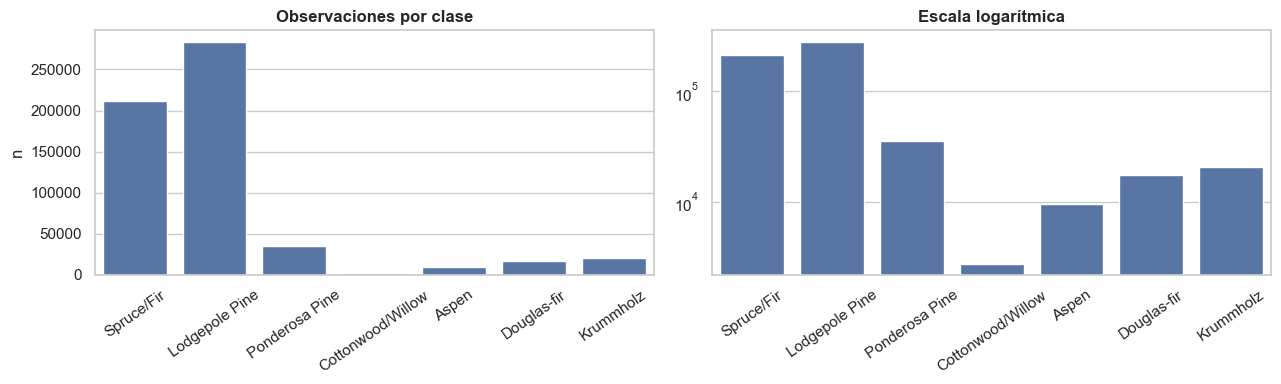

In [4]:
cnt = pd.Series(y).value_counts().sort_index()
tab = pd.DataFrame({"cobertura": NAMES, "n": cnt.values, "proporción %": 100 * cnt.values / len(y)}, index=CLASSES)
display(tab)
ratio = cnt.max() / cnt.min()
print(f"Razón de desbalance (mayor/menor): {ratio:.1f} : 1")
print(f"Exactitud de predecir siempre 'Lodgepole Pine': {cnt.max()/len(y):.3f}  -> macro-F1 de ese clasificador ≈ {2*(cnt.max()/len(y))/(1+cnt.max()/len(y))/7:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=NAMES, y=cnt.values, ax=ax[0], color="#4C72B0")
ax[0].set_title("Observaciones por clase"); ax[0].tick_params(axis="x", rotation=35); ax[0].set_ylabel("n")
sns.barplot(x=NAMES, y=cnt.values, ax=ax[1], color="#4C72B0"); ax[1].set_yscale("log")
ax[1].set_title("Escala logarítmica"); ax[1].tick_params(axis="x", rotation=35)
plt.tight_layout(); savefig("01_desbalance"); plt.show()
RESULTS["class_counts"] = {int(k): int(v) for k, v in cnt.items()}

### 1.2 Variables continuas, integridad de las indicadoras y colinealidad

In [5]:
display(df[F.CONTINUOUS].describe().T)

wsum = df[F.WILDERNESS].sum(axis=1); ssum = df[F.SOIL].sum(axis=1)
print("Filas con exactamente 1 área silvestre:", (wsum == 1).mean())
print("Filas con exactamente 1 tipo de suelo :", (ssum == 1).mean())
soil_prev = df[F.SOIL].mean().sort_values()
print("\nTipos de suelo más raros (proporción):")
print(soil_prev.head(6).round(5).to_string())

,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.3653,279.9847,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.6568,111.9137,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.1037,7.4882,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.4282,212.5494,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.4189,58.2952,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.1466,1559.2549,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.1460,26.7699,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.3187,19.7687,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.5283,38.2745,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.2912,1324.1952,0.0,1024.0,1710.0,2550.0,7173.0


Filas con exactamente 1 área silvestre: 1.0
Filas con exactamente 1 tipo de suelo : 1.0

Tipos de suelo más raros (proporción):
Soil_Type15    1.0000e-05
Soil_Type7     1.8000e-04
Soil_Type36    2.0000e-04
Soil_Type8     3.1000e-04
Soil_Type37    5.1000e-04
Soil_Type25    8.2000e-04


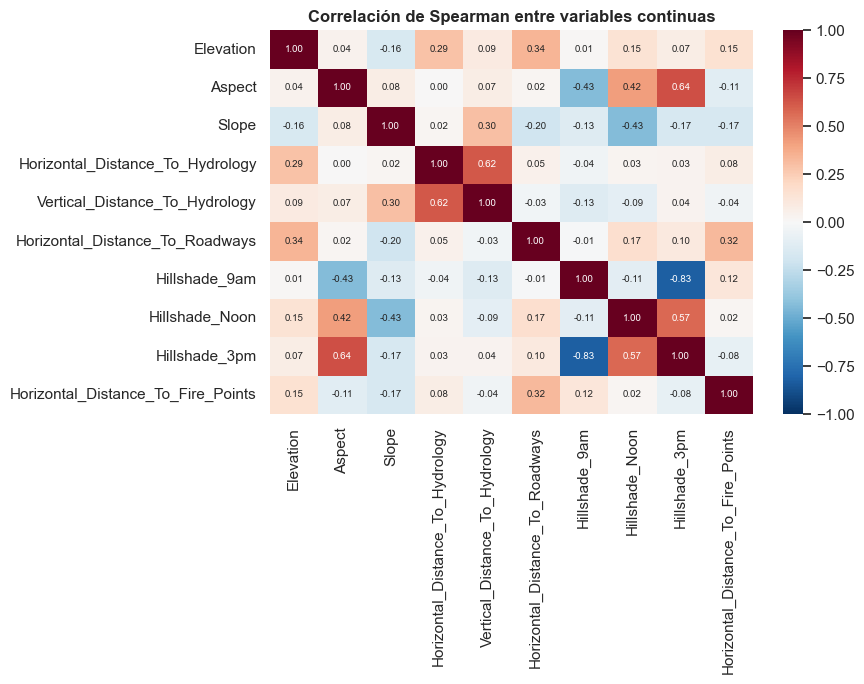

,level_0,level_1,rho
40,Hillshade_9am,Hillshade_3pm,-0.8268
15,Aspect,Hillshade_3pm,0.6409
24,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,0.6205
42,Hillshade_Noon,Hillshade_3pm,0.5737


,VIF
Hillshade_3pm,124.9327
Hillshade_9am,89.8283
Hillshade_Noon,32.5207
Slope,6.1388
Aspect,1.8479
Vertical_Distance_To_Hydrology,1.8078
Horizontal_Distance_To_Hydrology,1.7925
Elevation,1.3252
Horizontal_Distance_To_Roadways,1.2978
Horizontal_Distance_To_Fire_Points,1.1635


In [6]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

corr = df[F.CONTINUOUS].sample(100_000, random_state=SEED).corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax, vmin=-1, vmax=1)
ax.set_title("Correlación de Spearman entre variables continuas"); plt.tight_layout(); savefig("02_correlacion"); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().rename("rho").reset_index())
display(pairs.loc[pairs.rho.abs() > 0.5].sort_values("rho", key=abs, ascending=False))

Zv = sm.add_constant(df[F.CONTINUOUS].sample(50_000, random_state=SEED).astype(float))
vif = pd.Series([variance_inflation_factor(Zv.values, i) for i in range(1, Zv.shape[1])], index=F.CONTINUOUS, name="VIF")
display(vif.sort_values(ascending=False).to_frame())

Los índices de sombreado son funciones casi deterministas de la orientación y la pendiente (geometría solar), por eso
`Hillshade_9am` y `Hillshade_3pm` están fuertemente anticorrelacionadas y tienen los VIF más altos. Esta colinealidad no
afecta a los árboles, pero sí a la interpretación de coeficientes lineales; en la SVM con kernel RBF se traduce en
direcciones redundantes del espacio de entrada.

### 1.3 Valores atípicos por clase (regla de Tukey, 1.5·IQR dentro de cada clase)

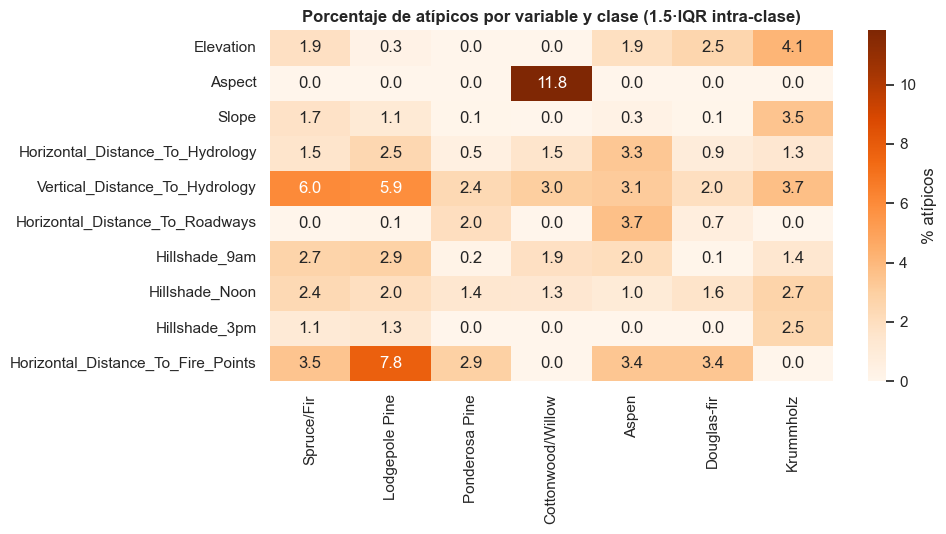

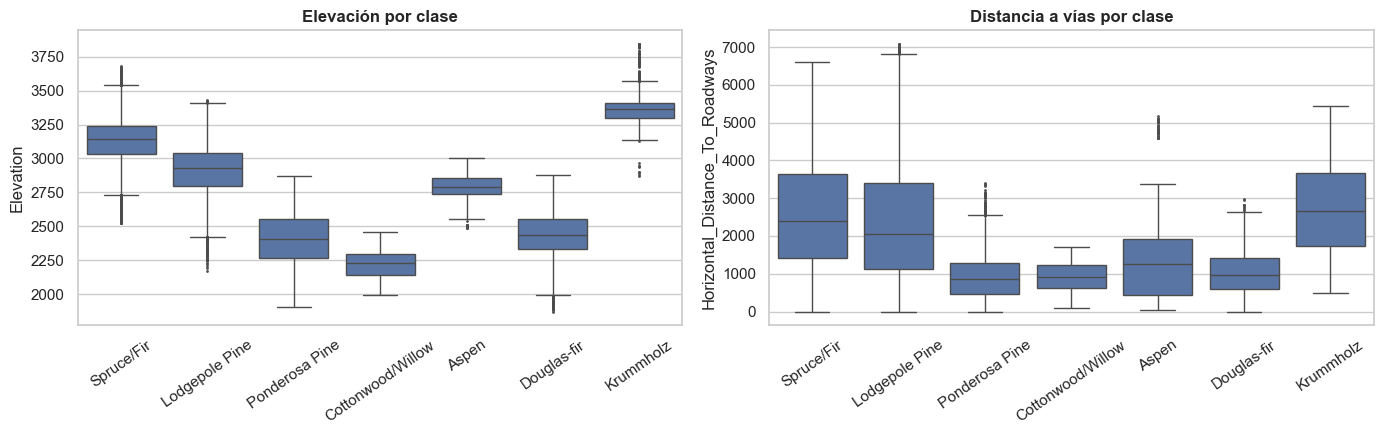

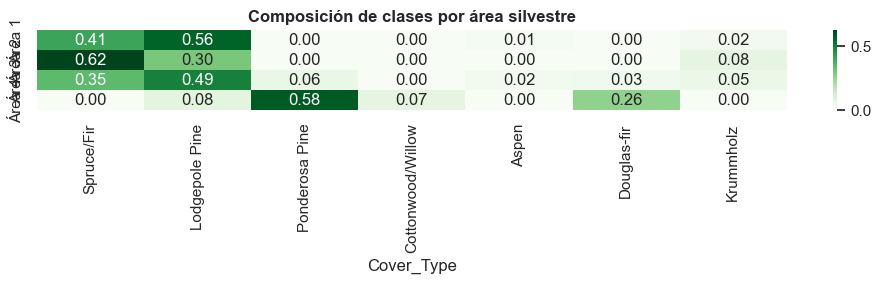

In [7]:
out = {}
for c in CLASSES:
    sub = df.loc[df[F.TARGET] == c, F.CONTINUOUS]
    q1, q3 = sub.quantile(0.25), sub.quantile(0.75); iqr = q3 - q1
    out[F.CLASS_NAMES[c]] = ((sub < q1 - 1.5 * iqr) | (sub > q3 + 1.5 * iqr)).mean() * 100
out = pd.DataFrame(out)
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(out, annot=True, fmt=".1f", cmap="Oranges", ax=ax, cbar_kws={"label": "% atípicos"})
ax.set_title("Porcentaje de atípicos por variable y clase (1.5·IQR intra-clase)")
plt.tight_layout(); savefig("03_atipicos"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
samp = df.sample(60_000, random_state=SEED).assign(clase=lambda d: d[F.TARGET].map(F.CLASS_NAMES))
sns.boxplot(data=samp, x="clase", y="Elevation", ax=ax[0], order=NAMES, fliersize=1)
sns.boxplot(data=samp, x="clase", y="Horizontal_Distance_To_Roadways", ax=ax[1], order=NAMES, fliersize=1)
for a in ax: a.tick_params(axis="x", rotation=35); a.set_xlabel("")
ax[0].set_title("Elevación por clase"); ax[1].set_title("Distancia a vías por clase")
plt.tight_layout(); savefig("04_boxplots"); plt.show()

wild = pd.crosstab(df[F.WILDERNESS].values.argmax(1) + 1, df[F.TARGET].map(F.CLASS_NAMES), normalize="index")[NAMES]
wild.index = [f"Área {i}" for i in wild.index]
fig, ax = plt.subplots(figsize=(10, 3))
sns.heatmap(wild, annot=True, fmt=".2f", cmap="Greens", ax=ax); ax.set_title("Composición de clases por área silvestre")
plt.tight_layout(); savefig("05_areas"); plt.show()

Los "atípicos" no son errores de medición: las distancias a hidrología y a vías tienen colas largas por naturaleza, y una
parcela de *Krummholz* a baja elevación es rara pero real. Por eso **no se eliminan filas**; se usan escaladores estándar
dentro del pipeline y modelos robustos (kernel RBF acotado, árboles). La elevación separa casi por sí sola a
*Krummholz*, *Spruce/Fir* y *Ponderosa/Cottonwood*: es la variable dominante y será la que usemos para simular deriva.

### 1.4 Ingeniería de características con sentido físico
- **Orientación circular:** `Aspect` (0–360°) se reemplaza por `sin` y `cos`, porque 1° y 359° son vecinos.
- **Distancia euclidiana a la hidrología:** √(horizontal² + vertical²).
- **Elevación ajustada:** elevación − distancia vertical a la hidrología (cota del cauce más cercano).
- Solo las continuas se escalan (`ColumnTransformer`); las 44 indicadoras pasan intactas. Todo vive dentro del `Pipeline`.

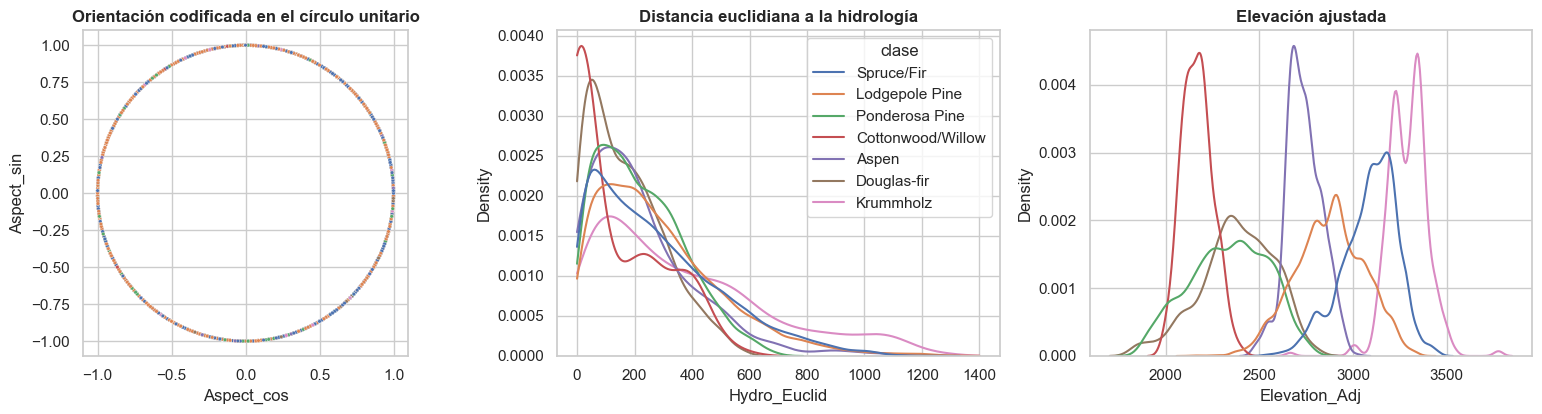

Salida del preprocesador: (5000, 57)
Medias de las escaladas (≈0): 0.026
Valores únicos de las indicadoras (deben ser {0,1}): [np.float32(0.0), np.float32(1.0)]


In [8]:
pf = F.PhysicalFeatures().fit(X.head(5))
eng = pf.transform(df.sample(40_000, random_state=SEED)[F.FEATURES])
eng["clase"] = df.loc[eng.index, F.TARGET].map(F.CLASS_NAMES)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
sns.scatterplot(data=eng.sample(6000, random_state=SEED), x="Aspect_cos", y="Aspect_sin", hue="clase", s=6, ax=ax[0], legend=False, hue_order=NAMES)
ax[0].set_title("Orientación codificada en el círculo unitario"); ax[0].set_aspect("equal")
sns.kdeplot(data=eng, x="Hydro_Euclid", hue="clase", common_norm=False, ax=ax[1], hue_order=NAMES, clip=(0, 1400))
ax[1].set_title("Distancia euclidiana a la hidrología")
sns.kdeplot(data=eng, x="Elevation_Adj", hue="clase", common_norm=False, ax=ax[2], hue_order=NAMES, legend=False)
ax[2].set_title("Elevación ajustada")
plt.tight_layout(); savefig("06_ingenieria"); plt.show()

prep = F.make_preprocessor().fit(X.sample(20_000, random_state=SEED))
Zs = pd.DataFrame(prep.transform(X.sample(5_000, random_state=1)), columns=prep.get_feature_names_out())
print("Salida del preprocesador:", Zs.shape)
print("Medias de las escaladas (≈0):", Zs[F.SCALED].mean().abs().max().round(3))
print("Valores únicos de las indicadoras (deben ser {0,1}):", sorted(np.unique(Zs[F.WILDERNESS + F.SOIL].values)))

### 1.5 Bloques pseudo-espaciales y particiones del protocolo
El conjunto no incluye coordenadas. Parcelas vecinas comparten elevación, vías y focos de incendio, así que agrupar con
KMeans (k = 20) en esas tres variables produce **bloques que aproximan regiones**. Validar por bloques obliga al modelo a
generalizar a zonas no vistas, en lugar de "reconocer" parcelas casi idénticas a las de entrenamiento.

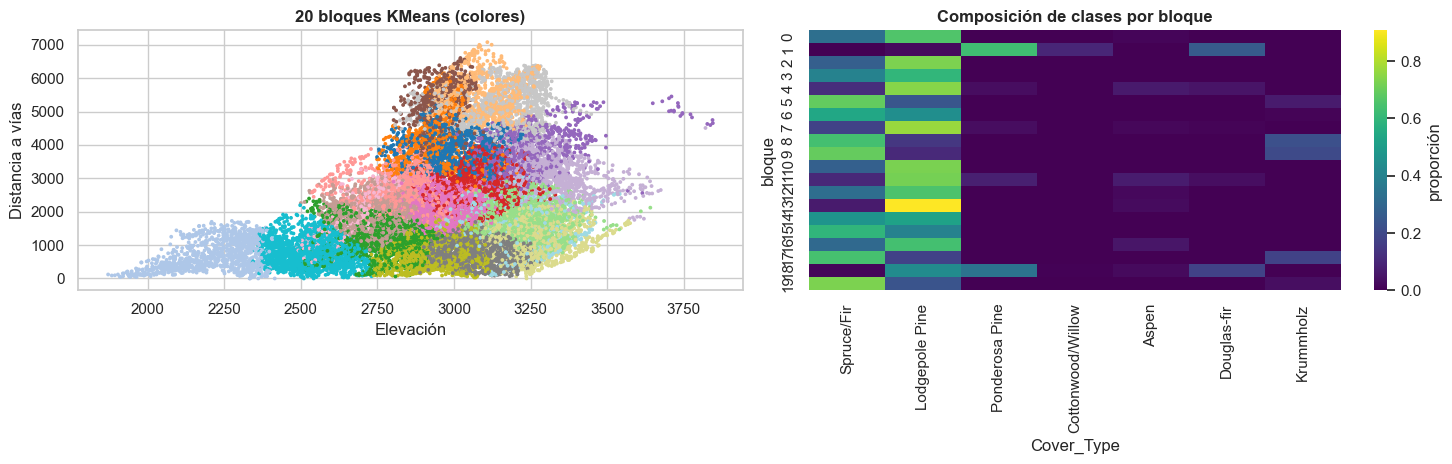

Tamaño de los bloques: [27025, 25750, 20928, 22947, 37542, 39677, 34611, 32127, 25466, 27504, 17677, 33311, 37549, 10544, 38000, 27505, 36200, 30949, 42453, 13247]


In [9]:
vcfg = cfg["validation"]
groups = V.make_blocks(df, vcfg["block_features"], k=vcfg["n_blocks"], seed=SEED)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
s = df.sample(25_000, random_state=SEED)
ax[0].scatter(s["Elevation"], s["Horizontal_Distance_To_Roadways"], c=groups[s.index], cmap="tab20", s=3)
ax[0].set_xlabel("Elevación"); ax[0].set_ylabel("Distancia a vías"); ax[0].set_title("20 bloques KMeans (colores)")
comp = pd.crosstab(groups, df[F.TARGET].map(F.CLASS_NAMES), normalize="index")[NAMES]
sns.heatmap(comp, cmap="viridis", ax=ax[1], cbar_kws={"label": "proporción"})
ax[1].set_title("Composición de clases por bloque"); ax[1].set_ylabel("bloque")
plt.tight_layout(); savefig("07_bloques"); plt.show()
print("Tamaño de los bloques:", np.bincount(groups).tolist())

In [10]:
pcfg = cfg["protocol"]
dev_idx, test_idx = V.holdout_by_blocks(y, groups, n_splits=pcfg["test_folds"], seed=SEED)
from sklearn.model_selection import train_test_split
rest, cal_idx = train_test_split(dev_idx, test_size=pcfg["conformal_calibration_size"], stratify=y[dev_idx], random_state=SEED)
devtrain_idx, iid_idx = train_test_split(rest, test_size=pcfg["iid_test_size"], stratify=y[rest], random_state=SEED)
devtrain_idx, cal_idx, iid_idx = np.sort(devtrain_idx), np.sort(cal_idx), np.sort(iid_idx)

assert len(np.intersect1d(np.unique(groups[test_idx]), np.unique(groups[dev_idx]))) == 0, "fuga de bloques"
for a, b in [(devtrain_idx, cal_idx), (devtrain_idx, iid_idx), (cal_idx, iid_idx), (dev_idx, test_idx)]:
    assert len(np.intersect1d(a, b)) == 0

parts = {"DEV-TRAIN": devtrain_idx, "CAL (conformal)": cal_idx, "IID (prueba aleatoria)": iid_idx, "TEST (bloques)": test_idx}
ptab = pd.DataFrame({k: pd.Series(y[v]).value_counts(normalize=True).sort_index() * 100 for k, v in parts.items()})
ptab.index = NAMES
ptab.loc["n filas"] = [len(v) for v in parts.values()]
ptab.loc["n bloques"] = [len(np.unique(groups[v])) for v in parts.values()]
display(ptab.round(2))
print("Bloques de prueba:", sorted(np.unique(groups[test_idx]).tolist()))
RESULTS["partitions"] = {k: int(len(v)) for k, v in parts.items()}
RESULTS["test_blocks"] = sorted(np.unique(groups[test_idx]).tolist())
log_run("fase1-eda", metrics={"imbalance_ratio": ratio, **{f"n_{k.split()[0]}": len(v) for k, v in parts.items()}},
        artifacts=[FIG / f for f in ["01_desbalance.png", "02_correlacion.png", "03_atipicos.png", "07_bloques.png"]])
print("Tiempo acumulado:", elapsed())

,DEV-TRAIN,CAL (conformal),IID (prueba aleatoria),TEST (bloques)
Spruce/Fir,33.00,33.00,33.00,47.37
Lodgepole Pine,49.79,49.79,49.79,45.52
Ponderosa Pine,7.89,7.89,7.89,0.67
Cottonwood/Willow,0.62,0.62,0.62,NaN
Aspen,2.03,2.03,2.03,0.39
Douglas-fir,3.87,3.88,3.88,0.20
Krummholz,2.79,2.79,2.80,5.85
n filas,411080.00,10000.00,20000.00,139932.00
n bloques,15.00,15.00,15.00,5.00


Bloques de prueba: [3, 5, 7, 9, 10]
Tiempo acumulado: 0.5 min


## 2. Fase 2 — Esquemas de validación (PI2)
Se comparan, **sobre los mismos datos de DEV-TRAIN**, tres esquemas:
(a) **aleatorio** estratificado (5 pliegues × 3 repeticiones), (b) **por bloques** con `GroupKFold` (5 × 3, permutando
los bloques en cada repetición) y (c) la **partición original de la UCI** (filas 1–11 340 entrenamiento, 11 341–15 120
validación), restringida a filas de DEV-TRAIN para no tocar la prueba. Tres modelos de referencia, cada uno como
`Pipeline` completo (el escalador se ajusta dentro de cada pliegue).

In [11]:
s_idx = V.stratified_subsample(devtrain_idx, y, vcfg["sample_size"], SEED)
Xs, ys, gs = X.iloc[s_idx].reset_index(drop=True), y[s_idx], groups[s_idx]
val_models = {
    "SVC-RBF": lambda: M.make_svc("rbf", C=10.0),
    "LogReg": lambda: M.make_logreg(C=1.0),
    "HGB": lambda: M.make_hgb(SEED, max_iter=150),
}
rows = []
split_cache = {}
for scheme in ["aleatorio", "bloques"]:
    split_cache[scheme] = V.scheme_splits(scheme, ys, gs, vcfg["n_splits"], vcfg["n_repeats"], SEED)
    for name, mk in val_models.items():
        t = time.perf_counter()
        rows += V.run_cv(mk(), Xs, ys, split_cache[scheme], scheme, name)
        print(f"{scheme:<10} {name:<8} {time.perf_counter()-t:6.1f} s")

uci_tr, uci_va, _ = V.uci_split(len(df))
uci_tr, uci_va = np.intersect1d(uci_tr, devtrain_idx), np.intersect1d(uci_va, devtrain_idx)
for name, mk in val_models.items():
    m = mk().fit(X.iloc[uci_tr], y[uci_tr])
    sc = V.scores(y[uci_va], m.predict(X.iloc[uci_va]))
    rows.append(V.FoldResult("UCI", name, 0, len(uci_tr), len(uci_va), fit_time=np.nan, **sc))
cvdf = pd.DataFrame([r.__dict__ for r in rows])
print(f"UCI: entrenamiento {len(uci_tr)} filas, validación {len(uci_va)} filas (distribución de clases de la UCI-train:",
      np.bincount(y[uci_tr])[1:].tolist(), ")")
summ = cvdf.groupby(["model", "scheme"])[["macro_f1", "balanced_accuracy", "mcc", "accuracy"]].agg(["mean", "std"]).round(4)
display(summ)

aleatorio  SVC-RBF    59.4 s


aleatorio  LogReg      8.6 s


aleatorio  HGB        45.1 s


bloques    SVC-RBF    47.1 s


bloques    LogReg      8.6 s


bloques    HGB        57.4 s


UCI: entrenamiento 8992 filas, validación 3018 filas (distribución de clases de la UCI-train: [1015, 1160, 1463, 1514, 1427, 1480, 933] )


macro_f1         balanced_accuracy             mcc         accuracy        
                      mean     std              mean     std    mean     std     mean     std
model   scheme                                                                               
HGB     UCI         0.8569     NaN            0.8583     NaN  0.8394     NaN   0.8628     NaN
        aleatorio   0.7121  0.0263            0.6716  0.0296  0.6930  0.0142   0.8082  0.0088
        bloques     0.3585  0.1050            0.4036  0.1242  0.3851  0.0456   0.6404  0.1182
LogReg  UCI         0.7171     NaN            0.7190     NaN  0.6647     NaN   0.7137     NaN
        aleatorio   0.5342  0.0310            0.5111  0.0303  0.5581  0.0173   0.7259  0.0105
        bloques     0.3956  0.1151            0.4138  0.1242  0.4191  0.0443   0.6744  0.0514
SVC-RBF UCI         0.8265     NaN            0.8278     NaN  0.7986     NaN   0.8280     NaN
        aleatorio   0.6747  0.0248            0.6415  0.0267  0.6640  0.0167   0.7903  0.0104
        bloques     0.4127  0.0517            0.4605  0.0904  0.3474  0.0414   0.6233  0.0905

,modelo,macro-F1 aleatorio,macro-F1 bloques,Δ (optimismo),IC95 inf,IC95 sup,optimismo relativo %
0,SVC-RBF,0.6747,0.4127,0.2620,0.1928,0.3312,63.4919
1,LogReg,0.5342,0.3956,0.1386,-0.0053,0.2825,35.0231
2,HGB,0.7121,0.3585,0.3536,0.2230,0.4843,98.6568


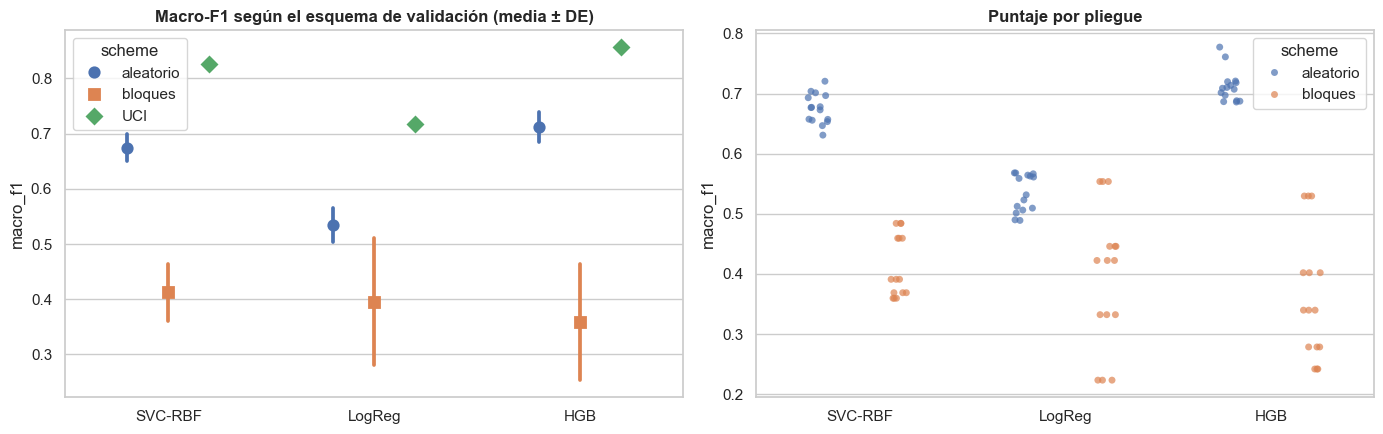

In [12]:
k = vcfg["n_splits"] * vcfg["n_repeats"]
n_te = len(ys) / vcfg["n_splits"]; n_tr = len(ys) - n_te
from scipy import stats as st
opt_rows = []
for name in val_models:
    a = cvdf.query("model == @name and scheme == 'aleatorio'").macro_f1.to_numpy()
    b = cvdf.query("model == @name and scheme == 'bloques'").macro_f1.to_numpy()
    # varianza corregida de Nadeau–Bengio para cada esquema (los pliegues repetidos están correlacionados)
    va = (1 / k + n_te / n_tr) * a.var(ddof=1); vb = (1 / k + n_te / n_tr) * b.var(ddof=1)
    delta = a.mean() - b.mean(); se = np.sqrt(va + vb); tq = st.t.ppf(0.975, k - 1)
    opt_rows.append({"modelo": name, "macro-F1 aleatorio": a.mean(), "macro-F1 bloques": b.mean(),
                     "Δ (optimismo)": delta, "IC95 inf": delta - tq * se, "IC95 sup": delta + tq * se,
                     "optimismo relativo %": 100 * delta / b.mean()})
opt = pd.DataFrame(opt_rows); display(opt.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.pointplot(data=cvdf, x="model", y="macro_f1", hue="scheme", dodge=0.4, errorbar="sd", ax=ax[0], linestyle="none",
              hue_order=["aleatorio", "bloques", "UCI"], markers=["o", "s", "D"])
ax[0].set_title("Macro-F1 según el esquema de validación (media ± DE)"); ax[0].set_xlabel("")
sns.stripplot(data=cvdf[cvdf.scheme != "UCI"], x="model", y="macro_f1", hue="scheme", dodge=True, ax=ax[1], alpha=.7)
ax[1].set_title("Puntaje por pliegue"); ax[1].set_xlabel("")
plt.tight_layout(); savefig("08_esquemas_validacion"); plt.show()
RESULTS["validation_schemes"] = cvdf.groupby(["model", "scheme"])["macro_f1"].agg(["mean", "std"]).reset_index().to_dict("records")
RESULTS["optimism"] = opt.to_dict("records")

**¿Por qué la validación aleatoria es optimista?** Abajo se mide, para cada punto de validación, la distancia (en el
espacio preprocesado) a su vecino más cercano del entrenamiento. Con partición aleatoria, casi todo punto de
validación tiene un "gemelo" en el entrenamiento; con bloques, no.

,count,mean,std,min,10%,50%,90%,max
esquema,,,,,,,,
aleatorio,2000.0,0.936,0.409,0.059,0.459,0.881,1.509,3.232
bloques,2000.0,2.149,0.852,0.387,1.095,2.112,3.320,5.027


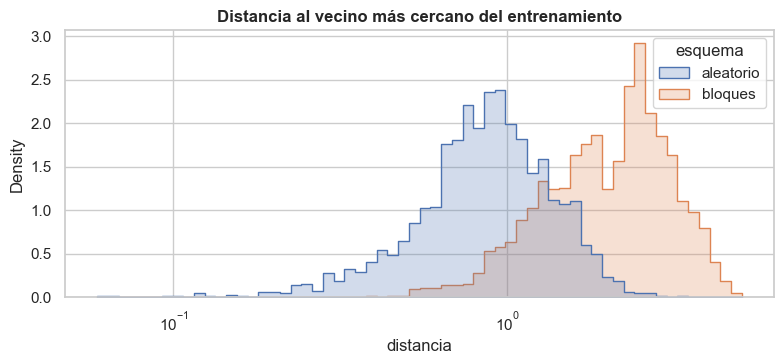

Tiempo acumulado: 4.4 min


In [13]:
from sklearn.neighbors import NearestNeighbors
prep_nn = F.make_preprocessor().fit(Xs)
Z = prep_nn.transform(Xs)
nn_rows = []
for scheme in ["aleatorio", "bloques"]:
    tr, te = split_cache[scheme][0]
    d, _ = NearestNeighbors(n_neighbors=1).fit(Z[tr]).kneighbors(Z[te][:2000])
    nn_rows.append(pd.DataFrame({"esquema": scheme, "distancia": d[:, 0]}))
nn = pd.concat(nn_rows)
display(nn.groupby("esquema")["distancia"].describe(percentiles=[.1, .5, .9]).round(3))
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(data=nn, x="distancia", hue="esquema", bins=60, log_scale=(True, False), element="step", stat="density", common_norm=False, ax=ax)
ax.set_title("Distancia al vecino más cercano del entrenamiento"); plt.tight_layout(); savefig("09_vecinos"); plt.show()
log_run("fase2-validacion", metrics={f"optimism_{r['modelo']}": r["Δ (optimismo)"] for r in opt_rows},
        artifacts=[FIG / "08_esquemas_validacion.png", FIG / "09_vecinos.png"])
print("Tiempo acumulado:", elapsed())

## 3. Fase 3 — Modelado y escalabilidad (PI1)
### 3.1 SVM exacta: tiempo, memoria y desempeño al crecer n
Se entrena `SVC` con kernels lineal, RBF y polinómico (grado 3), `C = 1`, `gamma = "scale"`, sobre submuestras estratificadas de
DEV-TRAIN. La evaluación se hace en un conjunto fijo de **bloques de validación** (bloques de DEV-TRAIN que no aportan filas de entrenamiento).

In [14]:
sc_cfg = cfg["scalability"]
fit_rel, val_rel = V.holdout_by_blocks(y[devtrain_idx], groups[devtrain_idx], n_splits=5, seed=SEED + 1)
fit_abs, val_abs = devtrain_idx[fit_rel], devtrain_idx[val_rel]
ev_idx = V.stratified_subsample(val_abs, y, sc_cfg["eval_size"], SEED)
Xev, yev = X.iloc[ev_idx], y[ev_idx]
print(f"Entrenamiento disponible: {len(fit_abs):,} filas · evaluación: {len(ev_idx):,} filas de {len(np.unique(groups[val_abs]))} bloques no vistos")

scal = []
for kernel in sc_cfg["kernels"]:
    for n in sc_cfg["sizes"]:
        tr = V.stratified_subsample(fit_abs, y, n, SEED)
        mdl = M.make_svc(kernel, C=1.0)
        with M.measure() as mf:
            mdl.fit(X.iloc[tr], y[tr])
        with M.measure() as mp:
            pred = mdl.predict(Xev)
        r = {"kernel": kernel, "n": n, "fit_s": mf["seconds"], "fit_mem_mb": mf["peak_mb"], "pred_s": mp["seconds"],
             "n_sv": int(mdl[-1].n_support_.sum()), **V.scores(yev, pred)}
        scal.append(r)
        print(f"{kernel:<6} n={n:>6}  ajuste {r['fit_s']:7.1f}s  pred {r['pred_s']:5.1f}s  SV={r['n_sv']:>6}  macro-F1={r['macro_f1']:.3f}")
scal = pd.DataFrame(scal)

Entrenamiento disponible: 333,974 filas · evaluación: 5,000 filas de 3 bloques no vistos


linear n=  2000  ajuste     0.2s  pred   0.2s  SV=  1328  macro-F1=0.323


linear n=  5000  ajuste     0.9s  pred   0.4s  SV=  3283  macro-F1=0.324


linear n= 10000  ajuste     5.1s  pred   1.0s  SV=  6465  macro-F1=0.327


linear n= 20000  ajuste    26.9s  pred   2.7s  SV= 12768  macro-F1=0.343


rbf    n=  2000  ajuste     0.1s  pred   0.7s  SV=  1471  macro-F1=0.290


... (3 outputs left out)

poly   n=  2000  ajuste     0.1s  pred   0.2s  SV=  1487  macro-F1=0.267


poly   n=  5000  ajuste     0.6s  pred   0.5s  SV=  3311  macro-F1=0.287


poly   n= 10000  ajuste     3.3s  pred   1.0s  SV=  6122  macro-F1=0.292


poly   n= 20000  ajuste    21.2s  pred   2.4s  SV= 11404  macro-F1=0.294


,kernel,b (ajuste),IC95 inf,IC95 sup,b (predicción)
0,linear,2.121,1.368,2.873,1.182
1,poly,2.232,1.484,2.981,1.050
2,rbf,2.204,1.672,2.736,0.926


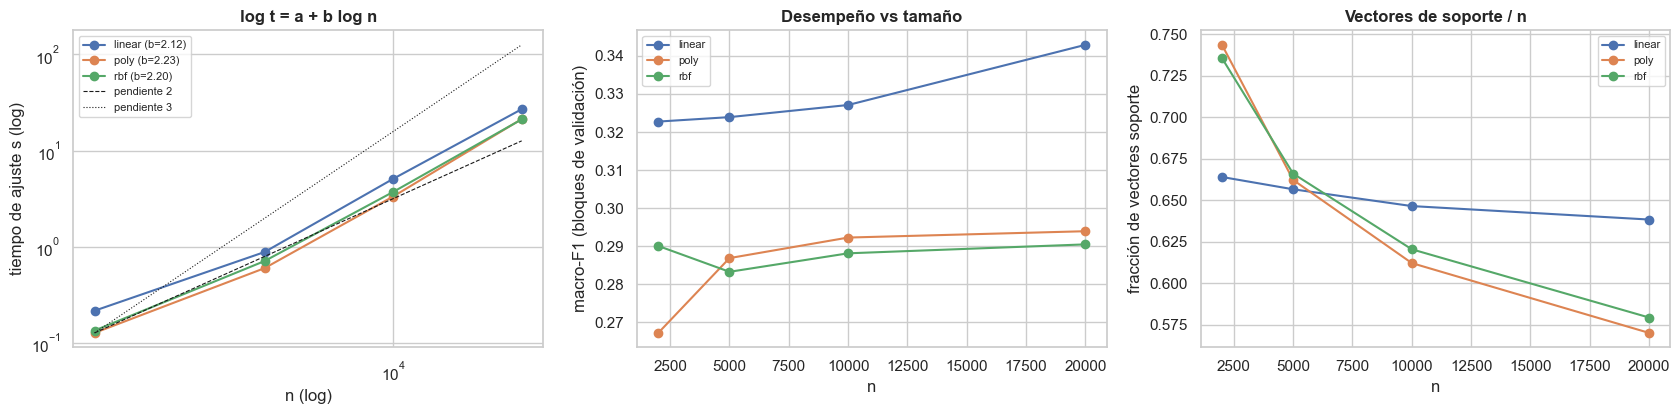

,kernel,n,fit_s,fit_mem_mb,pred_s,n_sv,macro_f1,balanced_accuracy,mcc,accuracy
0,linear,2000,0.214,5.824,0.174,1328,0.323,0.311,0.397,0.714
1,linear,5000,0.876,29.695,0.421,3283,0.324,0.304,0.422,0.725
2,linear,10000,5.066,139.926,0.958,6465,0.327,0.301,0.431,0.729
3,linear,20000,26.930,515.875,2.686,12768,0.343,0.320,0.437,0.732
4,rbf,2000,0.133,1.648,0.695,1471,0.290,0.271,0.374,0.699
5,rbf,5000,0.705,3.289,1.590,3330,0.283,0.268,0.385,0.704
6,rbf,10000,3.701,63.578,2.947,6205,0.288,0.268,0.386,0.704
7,rbf,20000,21.094,473.395,5.934,11589,0.290,0.270,0.366,0.694
8,poly,2000,0.126,0.031,0.213,1487,0.267,0.250,0.315,0.679
9,poly,5000,0.595,3.293,0.466,3311,0.287,0.267,0.338,0.688


In [15]:
fits = []
for kernel, g in scal.groupby("kernel"):
    a, b, (lo, hi) = M.fit_loglog(g.n, g.fit_s)
    a2, b2, _ = M.fit_loglog(g.n, g.pred_s)
    fits.append({"kernel": kernel, "b (ajuste)": b, "IC95 inf": lo, "IC95 sup": hi, "b (predicción)": b2})
fits = pd.DataFrame(fits); display(fits.round(3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for kernel, g in scal.groupby("kernel"):
    bb = fits.set_index("kernel").loc[kernel, "b (ajuste)"]
    ax[0].loglog(g.n, g.fit_s, "o-", label=f"{kernel} (b={bb:.2f})")
    ax[1].plot(g.n, g.macro_f1, "o-", label=kernel)
    ax[2].plot(g.n, g.n_sv / g.n, "o-", label=kernel)
nn_ = np.array(sc_cfg["sizes"], float)
ax[0].loglog(nn_, scal.fit_s.min() * (nn_ / nn_[0]) ** 2, "k--", lw=.8, label="pendiente 2")
ax[0].loglog(nn_, scal.fit_s.min() * (nn_ / nn_[0]) ** 3, "k:", lw=.8, label="pendiente 3")
ax[0].set(xlabel="n (log)", ylabel="tiempo de ajuste s (log)", title="log t = a + b log n")
ax[1].set(xlabel="n", ylabel="macro-F1 (bloques de validación)", title="Desempeño vs tamaño")
ax[2].set(xlabel="n", ylabel="fracción de vectores soporte", title="Vectores de soporte / n")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); savefig("10_escalabilidad_svc"); plt.show()
display(scal.round(3))
RESULTS["scalability"] = scal.to_dict("records"); RESULTS["complexity_fit"] = fits.to_dict("records")

### 3.2 Aproximaciones de kernel sobre todos los datos de entrenamiento y modelos de referencia
`Nystroem` (m puntos de referencia) y `RBFSampler` (características aleatorias de Fourier) proyectan los datos a un espacio de
dimensión m donde una SVM **lineal** aproxima a la SVM RBF. Para usar **todas** las filas de entrenamiento sin materializar
la matriz n × m (≈ 3 GB con m = 1 000), el clasificador `SGDClassifier(loss="hinge")` se entrena por bloques con `partial_fit`
(`ChunkedKernelSGD` en `src/forest/models.py`). Referencias: regresión logística multinomial y `HistGradientBoostingClassifier`.

In [16]:
ap = cfg["approximations"]
fit_full = fit_abs if FULL_CAP is None else V.stratified_subsample(fit_abs, y, FULL_CAP, SEED)
Zg = F.make_preprocessor().fit(X.iloc[fit_full[:20000]]).transform(X.iloc[fit_full[:20000]])
GAMMA = float(1.0 / (Zg.shape[1] * Zg.var()))     # mismo criterio que gamma="scale" de SVC
print(f"gamma (criterio 'scale') = {GAMMA:.4f} · filas de entrenamiento: {len(fit_full):,}")

approx = []
def run_ref(label, family, mdl, n_train):
    with M.measure() as mf:
        mdl.fit(X.iloc[n_train], y[n_train])
    with M.measure() as mp:
        pred = mdl.predict(Xev)
    r = {"modelo": label, "familia": family, "n_train": len(n_train), "fit_s": mf["seconds"], "fit_mem_mb": mf["peak_mb"],
         "pred_s": mp["seconds"], **V.scores(yev, pred)}
    approx.append(r)
    print(f"{label:<26} n={len(n_train):>7,}  ajuste {r['fit_s']:7.1f}s  mem {r['fit_mem_mb']:6.0f}MB  macro-F1={r['macro_f1']:.3f}")
    return mdl

for kind, label in [("nystroem", "Nyström"), ("rbf_sampler", "RFF")]:
    for m in ap["n_components"]:
        run_ref(f"{label} m={m} + SVM lineal", "aproximación", M.make_kernel_approx(kind, m, GAMMA, 1e-6, ap["n_epochs"], ap["chunk_size"], None, SEED), fit_full)
run_ref("LogReg multinomial", "referencia", M.make_logreg(C=1.0), fit_full)
run_ref("HGB", "referencia", M.make_hgb(SEED), fit_full)
best_svc = scal.query("kernel == 'rbf'").sort_values("n").iloc[-1]
approx.append({"modelo": f"SVC-RBF exacta n={int(best_svc.n)}", "familia": "SVM exacta", "n_train": int(best_svc.n),
               "fit_s": best_svc.fit_s, "fit_mem_mb": best_svc.fit_mem_mb, "pred_s": best_svc.pred_s,
               **{k: best_svc[k] for k in ["macro_f1", "balanced_accuracy", "mcc", "accuracy"]}})
approx = pd.DataFrame(approx)
display(approx.round(3))

gamma (criterio 'scale') = 0.0670 · filas de entrenamiento: 333,974


Nyström m=100 + SVM lineal n=333,974  ajuste     5.1s  mem    228MB  macro-F1=0.259


Nyström m=300 + SVM lineal n=333,974  ajuste    11.7s  mem    228MB  macro-F1=0.294


Nyström m=1000 + SVM lineal n=333,974  ajuste    36.9s  mem    269MB  macro-F1=0.485


RFF m=100 + SVM lineal     n=333,974  ajuste     3.7s  mem    228MB  macro-F1=0.188


RFF m=300 + SVM lineal     n=333,974  ajuste     6.5s  mem    228MB  macro-F1=0.272


RFF m=1000 + SVM lineal    n=333,974  ajuste    15.5s  mem    219MB  macro-F1=0.403


LogReg multinomial         n=333,974  ajuste    28.4s  mem    378MB  macro-F1=0.334


HGB                        n=333,974  ajuste   103.1s  mem    390MB  macro-F1=0.590


,modelo,familia,n_train,fit_s,fit_mem_mb,pred_s,macro_f1,balanced_accuracy,mcc,accuracy
0,Nyström m=100 + SVM lineal,aproximación,333974,5.122,228.453,0.017,0.259,0.290,0.337,0.684
1,Nyström m=300 + SVM lineal,aproximación,333974,11.740,228.449,0.045,0.294,0.320,0.323,0.680
2,Nyström m=1000 + SVM lineal,aproximación,333974,36.852,268.875,0.144,0.485,0.502,0.348,0.684
3,RFF m=100 + SVM lineal,aproximación,333974,3.659,228.445,0.009,0.188,0.269,0.158,0.614
4,RFF m=300 + SVM lineal,aproximación,333974,6.490,228.453,0.016,0.272,0.267,0.348,0.691
5,RFF m=1000 + SVM lineal,aproximación,333974,15.507,219.121,0.041,0.403,0.480,0.304,0.671
6,LogReg multinomial,referencia,333974,28.398,378.066,0.009,0.334,0.307,0.432,0.730
7,HGB,referencia,333974,103.141,389.715,0.298,0.590,0.518,0.406,0.711
8,SVC-RBF exacta n=20000,SVM exacta,20000,21.094,473.395,5.934,0.290,0.270,0.366,0.694


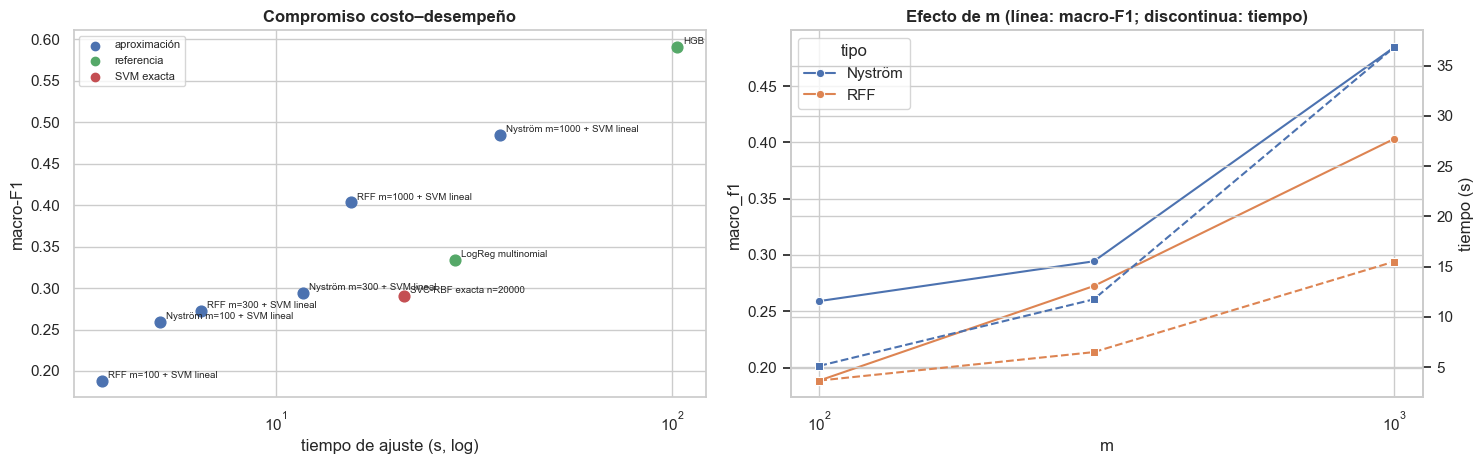

Tiempo acumulado: 9.8 min


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
pal = {"aproximación": "#4C72B0", "referencia": "#55A868", "SVM exacta": "#C44E52"}
for _, r in approx.iterrows():
    ax[0].scatter(r.fit_s, r.macro_f1, s=60, color=pal[r.familia])
    ax[0].annotate(r.modelo, (r.fit_s, r.macro_f1), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax[0].set_xscale("log"); ax[0].set(xlabel="tiempo de ajuste (s, log)", ylabel="macro-F1", title="Compromiso costo–desempeño")
for fam, c in pal.items(): ax[0].scatter([], [], color=c, label=fam)
ax[0].legend(fontsize=8)
nys = approx[approx.modelo.str.startswith(("Nyström", "RFF"))].copy()
nys["m"] = nys.modelo.str.extract(r"m=(\d+)").astype(int); nys["tipo"] = nys.modelo.str.split().str[0]
sns.lineplot(data=nys, x="m", y="macro_f1", hue="tipo", marker="o", ax=ax[1])
ax2 = ax[1].twinx(); sns.lineplot(data=nys, x="m", y="fit_s", hue="tipo", marker="s", ax=ax2, linestyle="--", legend=False)
ax[1].set_xscale("log"); ax[1].set_title("Efecto de m (línea: macro-F1; discontinua: tiempo)"); ax2.set_ylabel("tiempo (s)")
plt.tight_layout(); savefig("11_aproximaciones"); plt.show()
RESULTS["approximations"] = approx.to_dict("records")
log_run("fase3-escalabilidad", params={"gamma": GAMMA},
        metrics={**{f"b_{r['kernel']}": r["b (ajuste)"] for r in fits.to_dict("records")},
                 **{f"f1_{i}": v for i, v in enumerate(approx.macro_f1)}},
        artifacts=[FIG / "10_escalabilidad_svc.png", FIG / "11_aproximaciones.png"])
print("Tiempo acumulado:", elapsed())

### 3.3 Estrategias multiclase y desbalance
`SVC` entrena nativamente **uno contra uno** (OvO: 21 clasificadores binarios); `OneVsRestClassifier` entrena **uno contra el
resto** (OvR: 7 clasificadores, cada uno muy desbalanceado). Se cruzan con `class_weight=None` y `"balanced"` y se evalúan con
validación por bloques (5 pliegues).

,estrategia,tiempo_s,macro_f1,balanced_accuracy,mcc,accuracy
0,OvO · sin pesos,5.7165,0.4387,0.4075,0.4481,0.6563
1,OvO · balanced,5.4699,0.4428,0.4453,0.4437,0.6358
2,OvR · sin pesos,13.9161,0.4067,0.3865,0.4470,0.6557
3,OvR · balanced,19.1075,0.4130,0.4066,0.4444,0.6448


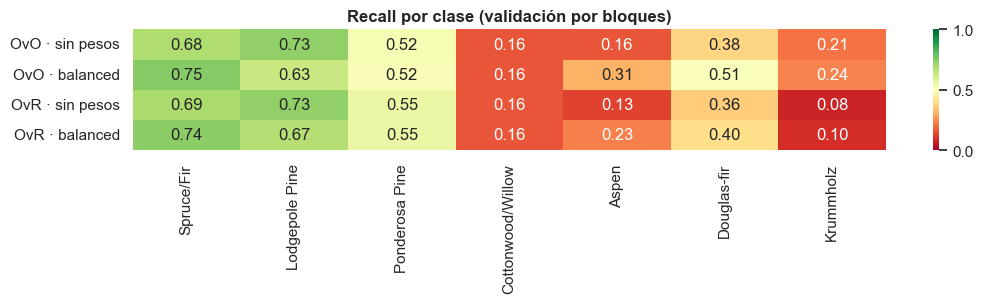

Tiempo acumulado: 10.5 min


In [18]:
from sklearn.metrics import recall_score
mc_idx = V.stratified_subsample(devtrain_idx, y, cfg["multiclass"]["sample_size"], SEED + 5)
Xm, ym, gm = X.iloc[mc_idx].reset_index(drop=True), y[mc_idx], groups[mc_idx]
splits_m = V.scheme_splits("bloques", ym, gm, 5, 1, SEED)
mc_rows, mc_rec = [], []
for strat, ovr in [("OvO", False), ("OvR", True)]:
    for cw in [None, "balanced"]:
        label = f"{strat} · {'balanced' if cw else 'sin pesos'}"
        t = time.perf_counter(); preds = np.empty_like(ym)
        for tr, te in splits_m:
            mdl = M.make_svc("rbf", C=10.0, class_weight=cw, ovr=ovr).fit(Xm.iloc[tr], ym[tr])
            preds[te] = mdl.predict(Xm.iloc[te])
        mc_rows.append({"estrategia": label, "tiempo_s": time.perf_counter() - t, **V.scores(ym, preds)})
        mc_rec.append(pd.Series(recall_score(ym, preds, labels=CLASSES, average=None, zero_division=0), index=NAMES, name=label))
mc = pd.DataFrame(mc_rows); display(mc.round(4))
rec = pd.DataFrame(mc_rec)
fig, ax = plt.subplots(figsize=(11, 3.2))
sns.heatmap(rec, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax); ax.set_title("Recall por clase (validación por bloques)")
plt.tight_layout(); savefig("12_multiclase"); plt.show()
RESULTS["multiclass"] = mc.to_dict("records")
print("Tiempo acumulado:", elapsed())

## 4. Fase 4 — Optimización de hiperparámetros con validación anidada
- **SVM lineal:** espacio pequeño ⇒ `GridSearchCV` sobre `C` (`LinearSVC`, pérdida bisagra).
- **SVM RBF:** `HalvingRandomSearchCV` con 60 candidatos, `C ~ logU(10⁻¹, 10³)`, `gamma ~ logU(10⁻³, 10⁰)`.
- **HGB:** `HalvingRandomSearchCV` sobre tasa de aprendizaje, hojas, mínimo por hoja y regularización L2.

Validación **anidada 5 × 3 por bloques**: el pliegue externo (`GroupKFold`, 5) estima el desempeño; el interno
(`GroupKFold`, 3, con los grupos pasados a la búsqueda) elige hiperparámetros. Se reporta la media **y la dispersión**
entre pliegues externos.

**Selección del campeón (regla de la fase 0):** mayor macro-F1 medio en la validación anidada; si la diferencia con el
segundo **no** es significativa (t corregida de Nadeau–Bengio, p ≥ 0.05), se elige el **más barato de servir**, medido
como la mediana de la latencia de predicción por 1 000 filas en los pliegues externos. Todo con datos de desarrollo.

In [19]:
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import HalvingRandomSearchCV, GridSearchCV, GroupKFold
from scipy.stats import loguniform, randint
tn = cfg["tuning"]

def nested(name, make_search, idx):
    Xn, yn, gn = X.iloc[idx].reset_index(drop=True), y[idx], groups[idx]
    rows = []
    for i, (tr, te) in enumerate(GroupKFold(tn["outer_splits"]).split(Xn, yn, gn)):
        t = time.perf_counter()
        search = make_search().fit(Xn.iloc[tr], yn[tr], groups=gn[tr])
        tp = time.perf_counter()
        pred_te = search.predict(Xn.iloc[te])
        pred_ms = 1000 * (time.perf_counter() - tp) / len(te) * 1000   # costo de servir: ms por cada 1 000 filas
        sc = V.scores(yn[te], pred_te)
        rows.append({"modelo": name, "pliegue": i, **sc, "inner_best": search.best_score_,
                     "n_train": len(tr), "n_test": len(te), "pred_ms_1000": pred_ms,
                     "params": {k.replace("clf__", ""): (round(v, 5) if isinstance(v, float) else v) for k, v in search.best_params_.items()},
                     "tiempo_s": time.perf_counter() - t})
        print(f"{name:<9} pliegue {i}: macro-F1={sc['macro_f1']:.3f}  ({rows[-1]['tiempo_s']:.0f}s)  {rows[-1]['params']}")
    final = make_search().fit(Xn, yn, groups=gn)     # búsqueda final (no anidada) para fijar hiperparámetros
    return pd.DataFrame(rows), {k.replace("clf__", ""): v for k, v in final.best_params_.items()}

inner = lambda: GroupKFold(tn["inner_splits"])
svc_idx = V.stratified_subsample(devtrain_idx, y, tn["svc_sample_size"], SEED + 2)
hgb_idx = V.stratified_subsample(devtrain_idx, y, tn["hgb_sample_size"], SEED + 3)

search_lin = lambda: GridSearchCV(M.make_linear_svc(), {"clf__C": [0.01, 0.1, 1.0, 10.0, 100.0]}, cv=inner(), scoring="f1_macro", n_jobs=2)
search_rbf = lambda: HalvingRandomSearchCV(M.make_svc("rbf"), {"clf__C": loguniform(1e-1, 1e3), "clf__gamma": loguniform(1e-3, 1e0)},
                                           n_candidates=tn["n_candidates"], factor=3, cv=inner(), scoring="f1_macro",
                                           random_state=SEED, n_jobs=2)
search_hgb = lambda: HalvingRandomSearchCV(M.make_hgb(SEED, max_iter=200),
                                           {"clf__learning_rate": loguniform(0.03, 0.3), "clf__max_leaf_nodes": randint(15, 128),
                                            "clf__min_samples_leaf": randint(10, 100), "clf__l2_regularization": loguniform(1e-3, 10)},
                                           n_candidates=tn["hgb_candidates"], factor=3, cv=inner(), scoring="f1_macro",
                                           random_state=SEED, n_jobs=1)
nest_lin, best_lin = nested("LinearSVC", search_lin, svc_idx)
nest_rbf, best_rbf = nested("SVC-RBF", search_rbf, svc_idx)
nest_hgb, best_hgb = nested("HGB", search_hgb, hgb_idx)
nest = pd.concat([nest_lin, nest_rbf, nest_hgb], ignore_index=True)
print("Tiempo acumulado:", elapsed())

LinearSVC pliegue 0: macro-F1=0.282  (5s)  {'C': 10.0}


LinearSVC pliegue 1: macro-F1=0.429  (1s)  {'C': 100.0}


LinearSVC pliegue 2: macro-F1=0.391  (1s)  {'C': 100.0}


LinearSVC pliegue 3: macro-F1=0.332  (1s)  {'C': 100.0}


LinearSVC pliegue 4: macro-F1=0.437  (1s)  {'C': 100.0}


SVC-RBF   pliegue 0: macro-F1=0.325  (5s)  {'C': np.float64(12.3291), 'gamma': np.float64(0.01917)}


... (6 outputs left out)

HGB       pliegue 2: macro-F1=0.266  (3554s)  {'l2_regularization': np.float64(0.01765), 'learning_rate': np.float64(0.09935), 'max_leaf_nodes': 120, 'min_samples_leaf': 13}


HGB       pliegue 3: macro-F1=0.450  (42s)  {'l2_regularization': np.float64(0.00629), 'learning_rate': np.float64(0.09803), 'max_leaf_nodes': 78, 'min_samples_leaf': 12}


HGB       pliegue 4: macro-F1=0.409  (31s)  {'l2_regularization': np.float64(0.00629), 'learning_rate': np.float64(0.09803), 'max_leaf_nodes': 78, 'min_samples_leaf': 12}


Tiempo acumulado: 73.6 min


> **Nota de ejecución.** El pliegue 2 de HGB registra ≈ 3 554 s porque el equipo entró en reposo (*Modern Standby*) durante esa búsqueda. Ese tiempo de reloj no interviene en ninguna decisión ni métrica: la regla de selección usa la latencia de predicción de SVC-RBF y LinearSVC, medida con el equipo activo, y los puntajes por pliegue no dependen del tiempo.

macro_f1         balanced_accuracy             mcc        
              mean     std              mean     std    mean     std
modelo                                                              
HGB         0.3432  0.0818            0.3668  0.1092  0.4058  0.0540
LinearSVC   0.3741  0.0663            0.4109  0.0473  0.3562  0.0529
SVC-RBF     0.4065  0.0820            0.4071  0.0525  0.3658  0.0430

,modelo,pliegue,macro_f1,inner_best,params
0,LinearSVC,0,0.2817,0.4008,{'C': 10.0}
1,LinearSVC,1,0.4289,0.3905,{'C': 100.0}
2,LinearSVC,2,0.3908,0.3521,{'C': 100.0}
3,LinearSVC,3,0.3317,0.3377,{'C': 100.0}
4,LinearSVC,4,0.4372,0.3292,{'C': 100.0}
5,SVC-RBF,0,0.3248,0.3531,"{'C': 12.3291, 'gamma': 0.01917}"
6,SVC-RBF,1,0.4076,0.3204,"{'C': 28.01635, 'gamma': 0.00262}"
7,SVC-RBF,2,0.5381,0.3483,"{'C': 163.94127, 'gamma': 0.00363}"
8,SVC-RBF,3,0.3529,0.3903,"{'C': 12.3291, 'gamma': 0.01917}"
9,SVC-RBF,4,0.4090,0.3509,"{'C': 213.68329, 'gamma': 0.00434}"


Hiperparámetros finales: {
 "LinearSVC": {
  "C": 100.0
 },
 "SVC-RBF": {
  "C": 206.5142557895921,
  "gamma": 0.011756010900231853
 },
 "HGB": {
  "l2_regularization": 0.017654048052495083,
  "learning_rate": 0.09935489664217143,
  "max_leaf_nodes": 120,
  "min_samples_leaf": 13
 }
}


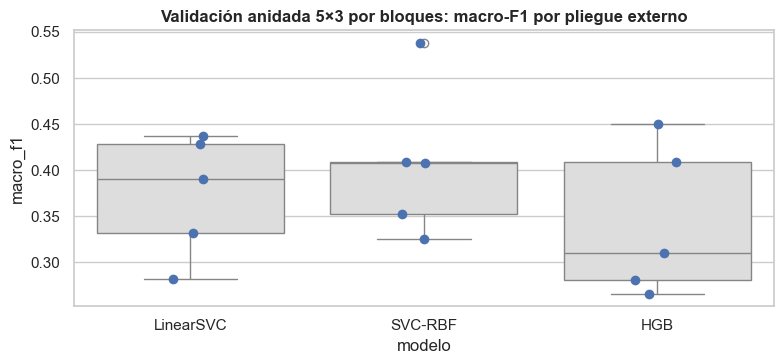

,macro-F1 anidada (media),latencia ms / 1 000 filas (mediana)
modelo,,
HGB,0.3432,26.8520
LinearSVC,0.3741,4.5064
SVC-RBF,0.4065,709.1105


SVC-RBF vs LinearSVC: Δ macro-F1 = 0.032, t corregida = 0.68, p = 0.532 (pareada)
Diferencia NO significativa ⇒ campeón = el más barato de servir: LinearSVC; alternativo: SVC-RBF


In [20]:
ns = nest.groupby("modelo")[["macro_f1", "balanced_accuracy", "mcc"]].agg(["mean", "std"])
display(ns.round(4))
display(nest[["modelo", "pliegue", "macro_f1", "inner_best", "params"]].round(4))
BEST = {"LinearSVC": best_lin, "SVC-RBF": best_rbf, "HGB": best_hgb}
print("Hiperparámetros finales:", json.dumps({k: {p: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for p, v in d.items()} for k, d in BEST.items()}, indent=1))

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=nest, x="modelo", y="macro_f1", ax=ax, color="#DDDDDD"); sns.stripplot(data=nest, x="modelo", y="macro_f1", ax=ax, size=7)
ax.set_title("Validación anidada 5×3 por bloques: macro-F1 por pliegue externo"); plt.tight_layout(); savefig("13_anidada"); plt.show()

# Regla de decisión fijada en la fase 0 (config.yaml), aplicada solo con datos de desarrollo (nunca con TEST):
#   1) se ordena por macro-F1 medio en la validación anidada;
#   2) si la diferencia entre el primero y el segundo NO es significativa (Nadeau–Bengio, p >= 0.05),
#      se elige el más barato de servir (mediana de la latencia de predicción en los pliegues externos).
nest_mean = nest.groupby("modelo").macro_f1.mean().sort_values(ascending=False)
serve_ms = nest.groupby("modelo").pred_ms_1000.median()
first, second = nest_mean.index[0], nest_mean.index[1]
fa = nest[nest.modelo == first].sort_values("pliegue"); fb = nest[nest.modelo == second].sort_values("pliegue")
n_tr_, n_te_ = fa.n_train.mean(), fa.n_test.mean()
from scipy import stats as st
SAMPLE_OF = {"LinearSVC": "svc_idx", "SVC-RBF": "svc_idx", "HGB": "hgb_idx"}   # submuestra de la búsqueda anidada
paired = SAMPLE_OF[first] == SAMPLE_OF[second] and np.array_equal(fa.n_test.to_numpy(), fb.n_test.to_numpy())
if paired:   # misma submuestra y mismos pliegues externos ⇒ diferencias pareadas por pliegue
    d_ = fa.macro_f1.to_numpy() - fb.macro_f1.to_numpy()
    t_sel, p_sel = V.corrected_ttest(d_, n_tr_, n_te_)
else:        # submuestras distintas ⇒ comparación no pareada con la misma corrección de varianza
    k_ = len(fa); c_ = 1 / k_ + n_te_ / n_tr_
    se_ = np.sqrt(c_ * (fa.macro_f1.var(ddof=1) + fb.macro_f1.var(ddof=1)))
    t_sel = (fa.macro_f1.mean() - fb.macro_f1.mean()) / se_
    p_sel = float(2 * st.t.sf(abs(t_sel), df=k_ - 1))
significant = p_sel < 0.05
CHAMPION = first if significant else min([first, second], key=lambda m: serve_ms[m])
ALT = "SVC-RBF" if CHAMPION != "SVC-RBF" else "HGB"   # el dashboard compara siempre con la SVM RBF (o con HGB)
SELECTION = {"primero": first, "segundo": second, "macro_f1_primero": float(nest_mean[first]),
             "macro_f1_segundo": float(nest_mean[second]), "pareada": bool(paired), "t": float(t_sel), "p": float(p_sel),
             "significativa": bool(significant), "ms_1000_primero": float(serve_ms[first]),
             "ms_1000_segundo": float(serve_ms[second]), "campeon": CHAMPION}
display(pd.DataFrame({"macro-F1 anidada (media)": nest_mean, "latencia ms / 1 000 filas (mediana)": serve_ms}).round(4))
print(f"{first} vs {second}: Δ macro-F1 = {nest_mean[first] - nest_mean[second]:.3f}, t corregida = {t_sel:.2f}, p = {p_sel:.3f} "
      f"({'pareada' if paired else 'no pareada'})")
print(("Diferencia significativa ⇒ campeón = mejor macro-F1" if significant else
       "Diferencia NO significativa ⇒ campeón = el más barato de servir") + f": {CHAMPION}; alternativo: {ALT}")
RESULTS["selection"] = SELECTION
RESULTS["nested"] = nest.drop(columns="params").to_dict("records")
RESULTS["best_params"] = {k: {p: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for p, v in d.items()} for k, d in BEST.items()}
RESULTS["champion"], RESULTS["alternative"] = CHAMPION, ALT
log_run("fase4-anidada", params={f"best_{k}": v for k, v in BEST.items()},
        metrics={f"nested_{k}_mean": v for k, v in nest_mean.items()}, artifacts=[FIG / "13_anidada.png"])

## 5. Fase 5 — Evaluación final
Se reentrenan los modelos con los hiperparámetros elegidos y se evalúan **una sola vez** en TEST (bloques no vistos) y en IID
(misma distribución que el entrenamiento). La SVM exacta usa una submuestra (su costo es ≈ cuadrático); la SVM lineal, las
aproximaciones y la regresión logística usan todo DEV-TRAIN; HGB usa una submuestra grande (límite de memoria del equipo).

In [21]:
fn = cfg["final"]
dev_full = devtrain_idx if FULL_CAP is None else V.stratified_subsample(devtrain_idx, y, FULL_CAP, SEED)
svc_tr = V.stratified_subsample(devtrain_idx, y, fn["svc_train_size"], SEED + 6)
hgb_tr = V.stratified_subsample(devtrain_idx, y, fn["hgb_train_size"], SEED + 7)
best_m = max(cfg["approximations"]["n_components"])
FACTORY = {
    "SVC-RBF": (lambda: M.make_svc("rbf", C=best_rbf["C"], gamma=best_rbf["gamma"]), svc_tr),
    "LinearSVC": (lambda: M.make_linear_svc(C=best_lin["C"]), dev_full),
    f"Nyström-{best_m}": (lambda: M.make_kernel_approx("nystroem", best_m, GAMMA, 1e-6, cfg["approximations"]["n_epochs"], 20000, None, SEED), dev_full),
    "LogReg": (lambda: M.make_logreg(C=1.0), dev_full),
    "HGB": (lambda: M.make_hgb(SEED, max_iter=300, **best_hgb), hgb_tr),
}
FINAL, FIT_TIME = {}, {}
for name, (mk, idx) in FACTORY.items():
    with M.measure() as mf:
        FINAL[name] = mk().fit(X.iloc[idx], y[idx])
    FIT_TIME[name] = mf["seconds"]
    print(f"{name:<14} n={len(idx):>7,}  ajuste {mf['seconds']:7.1f}s")

def scores_of(model, Xq):
    # Probabilidades si el modelo las tiene; si no, puntajes de decisión (para curvas ROC/PR)
    if hasattr(model, "predict_proba"):
        return model.predict_proba(Xq), True
    return model.decision_function(Xq), False

EVAL = {}
X_test, y_test, X_iid, y_iid = X.iloc[test_idx], y[test_idx], X.iloc[iid_idx], y[iid_idx]
for name, mdl in FINAL.items():
    t = time.perf_counter()
    s_te, is_p = scores_of(mdl, X_test); s_iid, _ = scores_of(mdl, X_iid)
    EVAL[name] = {"test_score": s_te, "iid_score": s_iid, "is_proba": is_p,
                  "test_pred": CLASSES[s_te.argmax(1)], "iid_pred": CLASSES[s_iid.argmax(1)], "pred_s": time.perf_counter() - t}
    print(f"{name:<14} predicción TEST+IID {EVAL[name]['pred_s']:6.1f}s")
print("Tiempo acumulado:", elapsed())

SVC-RBF        n= 20,000  ajuste    37.4s


LinearSVC      n=411,080  ajuste    28.7s


Nyström-1000   n=411,080  ajuste    46.6s


LogReg         n=411,080  ajuste    36.4s


HGB            n=150,000  ajuste    95.1s


SVC-RBF        predicción TEST+IID  164.5s
LinearSVC      predicción TEST+IID    0.2s


Nyström-1000   predicción TEST+IID    4.6s
LogReg         predicción TEST+IID    0.1s


HGB            predicción TEST+IID   11.3s
Tiempo acumulado: 80.7 min


**Métricas en TEST (bloques no vistos) e IID.** El log-loss de las SVM se reporta tras calibrar (§6).

,modelo,macro-F1 TEST,bal.acc TEST,MCC TEST,exactitud TEST,AUC macro,AUC micro,log-loss TEST,macro-F1 IID,brecha IID−TEST,ajuste s,pred s
4,HGB,0.4881,0.5823,0.4970,0.7103,0.9175,0.9562,1.1450,0.9202,0.4321,95.1122,11.3380
1,LinearSVC,0.4407,0.4328,0.4425,0.6799,0.8940,0.9483,NaN,0.4995,0.0589,28.6998,0.1900
2,Nyström-1000,0.4382,0.4748,0.4228,0.6594,0.8850,0.9312,NaN,0.6889,0.2507,46.6009,4.5862
0,SVC-RBF,0.4033,0.4561,0.4157,0.6569,0.8699,0.9444,NaN,0.6967,0.2933,37.3943,164.5417
3,LogReg,0.3998,0.4361,0.4382,0.6705,0.9002,0.9484,0.7656,0.5610,0.1613,36.4496,0.1355


**IC 95 % bootstrap (B = 1000) en TEST**

estimate                              ci_low                             ci_high                           
metric       accuracy balanced_accuracy macro_f1 accuracy balanced_accuracy macro_f1 accuracy balanced_accuracy macro_f1
modelo                                                                                                                  
HGB            0.7103            0.5823   0.4881   0.7079            0.5746   0.4783   0.7127            0.5904   0.4972
LinearSVC      0.6799            0.4328   0.4407   0.6773            0.4250   0.4303   0.6822            0.4399   0.4503
LogReg         0.6705            0.4361   0.3998   0.6679            0.4265   0.3929   0.6728            0.4447   0.4059
Nyström-1000   0.6594            0.4748   0.4382   0.6568            0.4636   0.4294   0.6618            0.4865   0.4471
SVC-RBF        0.6569            0.4561   0.4033   0.6545            0.4448   0.3960   0.6591            0.4671   0.4103

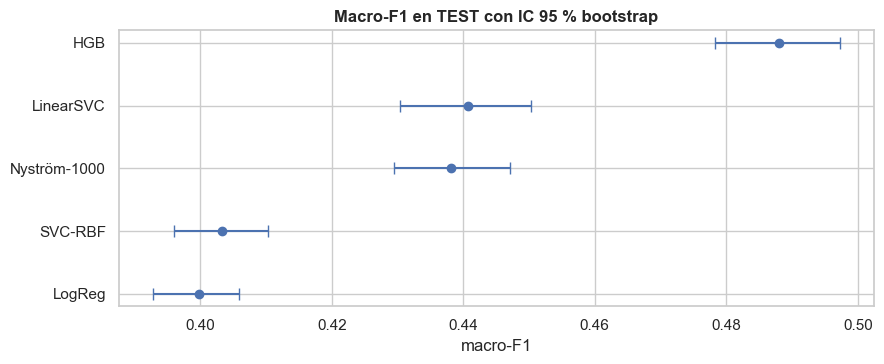

In [22]:
from sklearn.metrics import log_loss, roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, confusion_matrix, ConfusionMatrixDisplay
B = cfg["evaluation"]["bootstrap_B"]
Y_test = (y_test[:, None] == CLASSES[None, :]).astype(int)

def auc_macro_micro(Y, S):
    per = [roc_auc_score(Y[:, k], S[:, k]) for k in range(S.shape[1]) if 0 < Y[:, k].sum() < len(Y)]
    return float(np.mean(per)), float(roc_auc_score(Y.ravel(), S.ravel()))

ev_rows, ci_rows = [], []
for name, e in EVAL.items():
    ci = V.bootstrap_ci(y_test, e["test_pred"], CLASSES, B=B, seed=SEED).assign(modelo=name)
    ci_rows.append(ci)
    a_mac, a_mic = auc_macro_micro(Y_test, e["test_score"])
    st_ = V.scores(y_test, e["test_pred"]); si = V.scores(y_iid, e["iid_pred"])
    ev_rows.append({"modelo": name, "macro-F1 TEST": st_["macro_f1"], "bal.acc TEST": st_["balanced_accuracy"], "MCC TEST": st_["mcc"],
                    "exactitud TEST": st_["accuracy"], "AUC macro": a_mac, "AUC micro": a_mic,
                    "log-loss TEST": log_loss(y_test, e["test_score"], labels=CLASSES) if e["is_proba"] else np.nan,
                    "macro-F1 IID": si["macro_f1"], "brecha IID−TEST": si["macro_f1"] - st_["macro_f1"],
                    "ajuste s": FIT_TIME[name], "pred s": e["pred_s"]})
ev = pd.DataFrame(ev_rows).sort_values("macro-F1 TEST", ascending=False)
cis = pd.concat(ci_rows).pivot(index="modelo", columns="metric", values=["estimate", "ci_low", "ci_high"])
display(Markdown("**Métricas en TEST (bloques no vistos) e IID.** El log-loss de las SVM se reporta tras calibrar (§6)."))
display(ev.round(4))
display(Markdown(f"**IC 95 % bootstrap (B = {B}) en TEST**"))
display(cis.round(4))

fig, ax = plt.subplots(figsize=(9, 3.8))
c2 = pd.concat(ci_rows).query("metric == 'macro_f1'").sort_values("estimate")
ax.errorbar(c2.estimate, c2.modelo, xerr=[c2.estimate - c2.ci_low, c2.ci_high - c2.estimate], fmt="o", capsize=4)
ax.set_title("Macro-F1 en TEST con IC 95 % bootstrap"); ax.set_xlabel("macro-F1"); plt.tight_layout(); savefig("14_ic_bootstrap"); plt.show()
RESULTS["test_metrics"] = ev.to_dict("records"); RESULTS["test_ci"] = pd.concat(ci_rows).to_dict("records")

**Recall por clase en TEST**

,Spruce/Fir,Lodgepole Pine,Ponderosa Pine,Cottonwood/Willow,Aspen,Douglas-fir,Krummholz
SVC-RBF,0.594,0.728,0.269,0.0,0.000,0.441,0.704
LinearSVC,0.614,0.765,0.509,0.0,0.015,0.061,0.633
Nyström-1000,0.616,0.710,0.322,0.0,0.006,0.484,0.712
LogReg,0.614,0.734,0.314,0.0,0.000,0.222,0.732
HGB,0.706,0.729,0.359,0.0,0.070,0.953,0.677


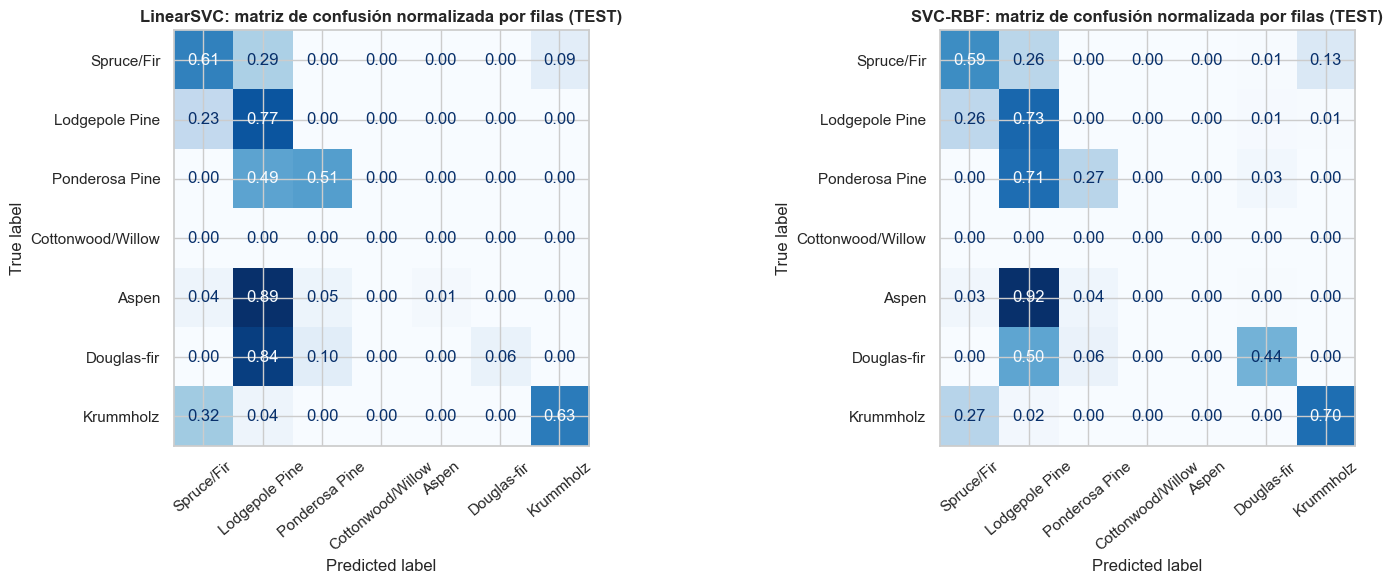

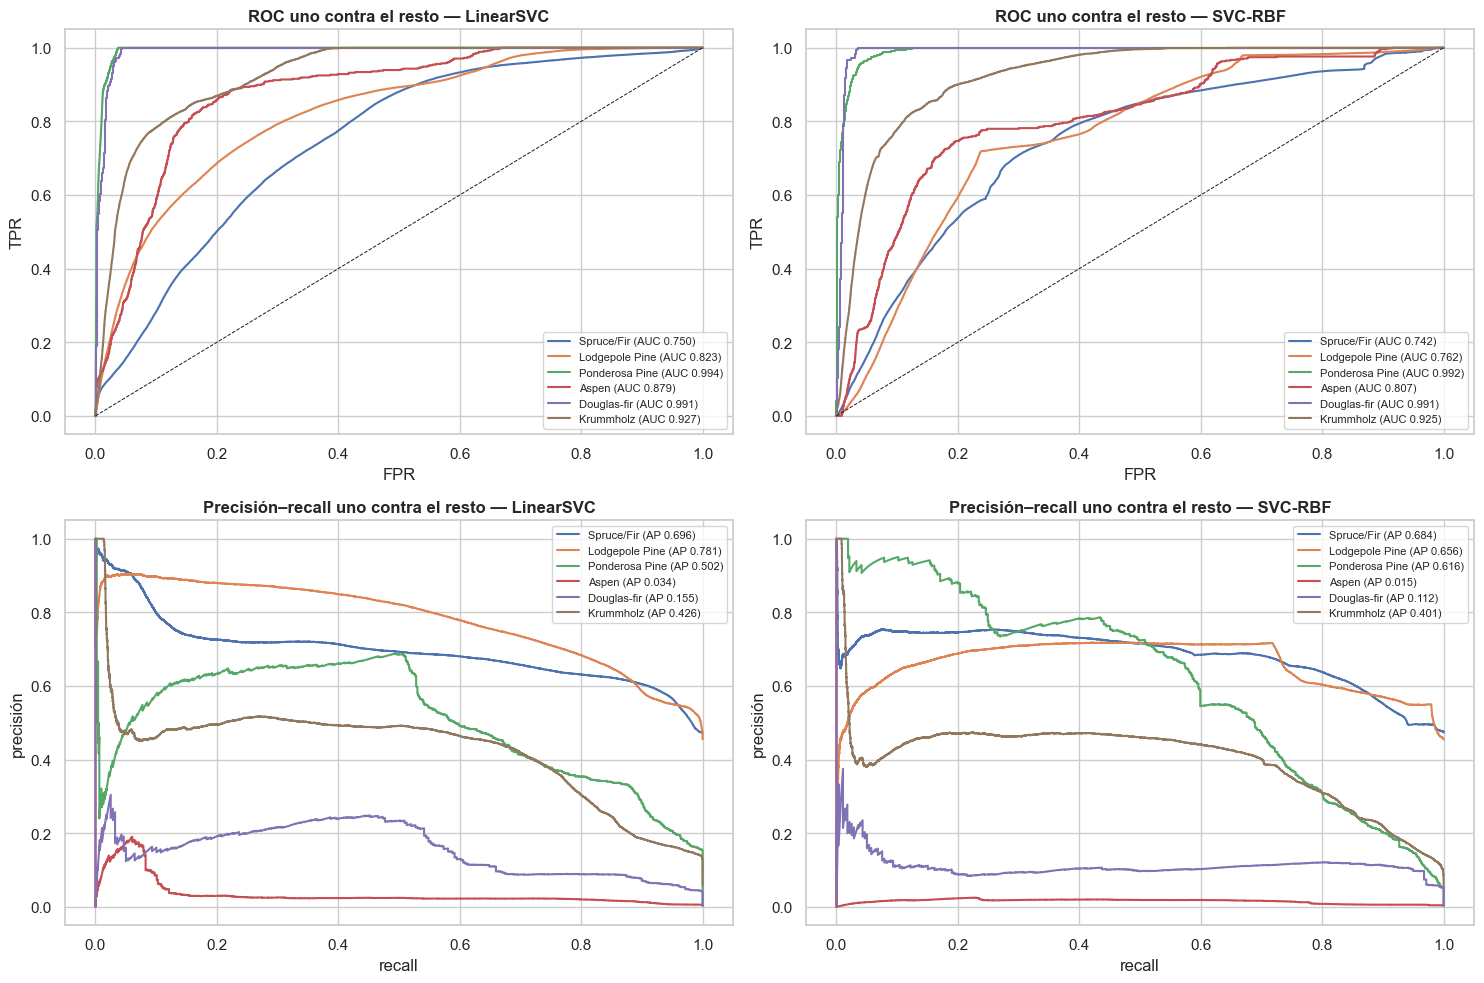

In [23]:
rec_tab = pd.DataFrame({name: recall_score(y_test, e["test_pred"], labels=CLASSES, average=None, zero_division=0) for name, e in EVAL.items()}, index=NAMES).T
display(Markdown("**Recall por clase en TEST**")); display(rec_tab.round(3))
RESULTS["recall_per_class"] = rec_tab.reset_index().rename(columns={"index": "modelo"}).to_dict("records")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, name in zip(ax, [CHAMPION, ALT]):
    ConfusionMatrixDisplay.from_predictions(y_test, EVAL[name]["test_pred"], labels=CLASSES, display_labels=NAMES, normalize="true",
                                            values_format=".2f", cmap="Blues", ax=a, colorbar=False)
    a.set_title(f"{name}: matriz de confusión normalizada por filas (TEST)"); a.tick_params(axis="x", rotation=40)
plt.tight_layout(); savefig("15_confusion"); plt.show()
RESULTS["confusion"] = {name: confusion_matrix(y_test, EVAL[name]["test_pred"], labels=CLASSES, normalize="true").round(4).tolist() for name in [CHAMPION, ALT]}

fig, ax = plt.subplots(2, 2, figsize=(15, 10))
for j, name in enumerate([CHAMPION, ALT]):
    S = EVAL[name]["test_score"]
    for k, cname in enumerate(NAMES):
        if Y_test[:, k].sum() == 0: continue
        fpr, tpr, _ = roc_curve(Y_test[:, k], S[:, k]); pr, rc, _ = precision_recall_curve(Y_test[:, k], S[:, k])
        ax[0, j].plot(fpr, tpr, label=f"{cname} (AUC {roc_auc_score(Y_test[:, k], S[:, k]):.3f})")
        ax[1, j].plot(rc, pr, label=f"{cname} (AP {average_precision_score(Y_test[:, k], S[:, k]):.3f})")
    ax[0, j].plot([0, 1], [0, 1], "k--", lw=.7); ax[0, j].set(title=f"ROC uno contra el resto — {name}", xlabel="FPR", ylabel="TPR")
    ax[1, j].set(title=f"Precisión–recall uno contra el resto — {name}", xlabel="recall", ylabel="precisión")
    ax[0, j].legend(fontsize=8); ax[1, j].legend(fontsize=8)
plt.tight_layout(); savefig("16_roc_pr"); plt.show()

### 5.1 Comparación estadística entre modelos
- **t corregida de Nadeau–Bengio** sobre los 15 pliegues **pareados** de la validación por bloques de la §2 (mismos pliegues
  para todos los modelos), con tamaño del efecto *d_z*.
- **McNemar** sobre TEST (mismas filas), con la razón de odds de discordancia como tamaño del efecto y la diferencia de
  macro-F1 con IC bootstrap pareado.

In [24]:
nb_rows = []
blk = cvdf[cvdf.scheme == "bloques"]
for a_, b_ in [("HGB", "SVC-RBF"), ("SVC-RBF", "LogReg"), ("HGB", "LogReg")]:
    d = blk[blk.model == a_].sort_values("fold").macro_f1.to_numpy() - blk[blk.model == b_].sort_values("fold").macro_f1.to_numpy()
    n_tr_ = blk[blk.model == a_].n_train.mean(); n_te_ = blk[blk.model == a_].n_test.mean()
    t_, p_ = V.corrected_ttest(d, n_tr_, n_te_)
    nb_rows.append({"A": a_, "B": b_, "Δ macro-F1 medio": d.mean(), "t corregida": t_, "p": p_, "d_z": V.cohens_dz(d), "k": len(d)})
nbt = pd.DataFrame(nb_rows); display(Markdown("**Nadeau–Bengio (validación por bloques 5×3)**")); display(nbt.round(4))

mc_rows = []
pairs_ = [(CHAMPION, ALT), ("SVC-RBF", f"Nyström-{best_m}"), (f"Nyström-{best_m}", "LinearSVC"), (CHAMPION, "LogReg")]
for a_, b_ in pairs_:
    if a_ == b_: continue
    r = V.mcnemar(y_test, EVAL[a_]["test_pred"], EVAL[b_]["test_pred"])
    d, lo, hi = V.paired_bootstrap_diff(y_test, EVAL[a_]["test_pred"], EVAL[b_]["test_pred"], CLASSES, B=B, seed=SEED)
    mc_rows.append({"A": a_, "B": b_, **r, "Δ macro-F1": d, "IC95 Δ inf": lo, "IC95 Δ sup": hi})
mcn = pd.DataFrame(mc_rows); display(Markdown("**McNemar en TEST**")); display(mcn.round(4))
RESULTS["nadeau_bengio"] = nbt.to_dict("records"); RESULTS["mcnemar"] = mcn.to_dict("records")
log_run("fase5-evaluacion", metrics={f"test_f1_{r['modelo']}": r["macro-F1 TEST"] for r in ev_rows},
        artifacts=[FIG / f for f in ["14_ic_bootstrap.png", "15_confusion.png", "16_roc_pr.png"]])
print("Tiempo acumulado:", elapsed())

**Nadeau–Bengio (validación por bloques 5×3)**

,A,B,Δ macro-F1 medio,t corregida,p,d_z,k
0,HGB,SVC-RBF,-0.0542,-0.9252,0.3705,-0.5206,15
1,SVC-RBF,LogReg,0.0170,0.2406,0.8133,0.1354,15
2,HGB,LogReg,-0.0372,-0.9513,0.3576,-0.5353,15


**McNemar en TEST**

,A,B,n_A_ok_B_fail,n_A_fail_B_ok,chi2,p_value,odds_ratio,Δ macro-F1,IC95 Δ inf,IC95 Δ sup
0,LinearSVC,SVC-RBF,15869,12644,364.5416,0.0000,1.2551,0.0373,0.0268,0.0474
1,SVC-RBF,Nyström-1000,9669,10013,5.9775,0.0145,0.9656,-0.0348,-0.0426,-0.0277
2,Nyström-1000,LinearSVC,13920,16801,269.9912,0.0000,0.8285,-0.0025,-0.0150,0.0102
3,LinearSVC,LogReg,7742,6418,123.6108,0.0000,1.2063,0.0409,0.0313,0.0504


Tiempo acumulado: 81.3 min


## 6. Fase 6 (extensión) — Calibración y predicción conforme (PI3)
### 6.1 Calibración con `CalibratedClassifierCV` (sigmoide e isotónica, cv = 5)
Se calibran el campeón y el modelo alternativo. Con `ensemble=False`, las 5 particiones generan predicciones fuera de
muestra para ajustar el calibrador y el modelo base se reentrena con todos los datos (un solo modelo que servir).

In [25]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold
cc = cfg["calibration"]
CALIB, cal_fit_time = {}, {}
for name in [CHAMPION, ALT]:
    mk, idx = FACTORY[name]
    for method in cc["methods"]:
        t = time.perf_counter()
        CALIB[(name, method)] = CalibratedClassifierCV(mk(), method=method, cv=StratifiedKFold(cc["cv"], shuffle=True, random_state=SEED),
                                                       ensemble=False).fit(X.iloc[idx], y[idx])
        cal_fit_time[(name, method)] = time.perf_counter() - t
        print(f"{name:<9} {method:<9} {cal_fit_time[(name, method)]:6.1f}s")

min_class = {name: int(np.bincount(y[FACTORY[name][1]])[1:].min()) for name in [CHAMPION, ALT]}
METHOD = {name: ("isotonic" if min_class[name] >= 1000 else "sigmoid") for name in [CHAMPION, ALT]}
print("Clase minoritaria en entrenamiento:", min_class, "-> método elegido por la regla del protocolo:", METHOD)

PROBA = {}
for (name, method), m in CALIB.items():
    PROBA[(name, method)] = {"test": m.predict_proba(X_test), "iid": m.predict_proba(X_iid), "cal": m.predict_proba(X.iloc[cal_idx])}
for name in [CHAMPION, ALT]:
    if EVAL[name]["is_proba"]:
        PROBA[(name, "sin calibrar")] = {"test": EVAL[name]["test_score"], "iid": EVAL[name]["iid_score"]}
print("Tiempo acumulado:", elapsed())

LinearSVC sigmoid    153.6s


LinearSVC isotonic   148.9s


SVC-RBF   sigmoid    152.2s


SVC-RBF   isotonic   156.6s
Clase minoritaria en entrenamiento: {'LinearSVC': 2561, 'SVC-RBF': 124} -> método elegido por la regla del protocolo: {'LinearSVC': 'isotonic', 'SVC-RBF': 'sigmoid'}


Tiempo acumulado: 97.9 min


,modelo,método,conjunto,ECE (15),ECE por clase (media),Brier,log-loss,macro-F1
2,LinearSVC,isotonic,IID,0.0189,0.0073,0.3914,0.6540,0.5279
0,LinearSVC,sigmoid,IID,0.0248,0.0110,0.3936,0.6634,0.5303
3,LinearSVC,isotonic,TEST,0.0364,0.0252,0.4319,0.7146,0.4671
1,LinearSVC,sigmoid,TEST,0.0348,0.0254,0.4311,0.6983,0.4433
6,SVC-RBF,isotonic,IID,0.0155,0.0069,0.3234,0.5548,0.6968
4,SVC-RBF,sigmoid,IID,0.0175,0.0066,0.3273,0.5610,0.6957
7,SVC-RBF,isotonic,TEST,0.1360,0.0417,0.4907,0.8184,0.4069
5,SVC-RBF,sigmoid,TEST,0.1350,0.0431,0.5013,0.8593,0.4080


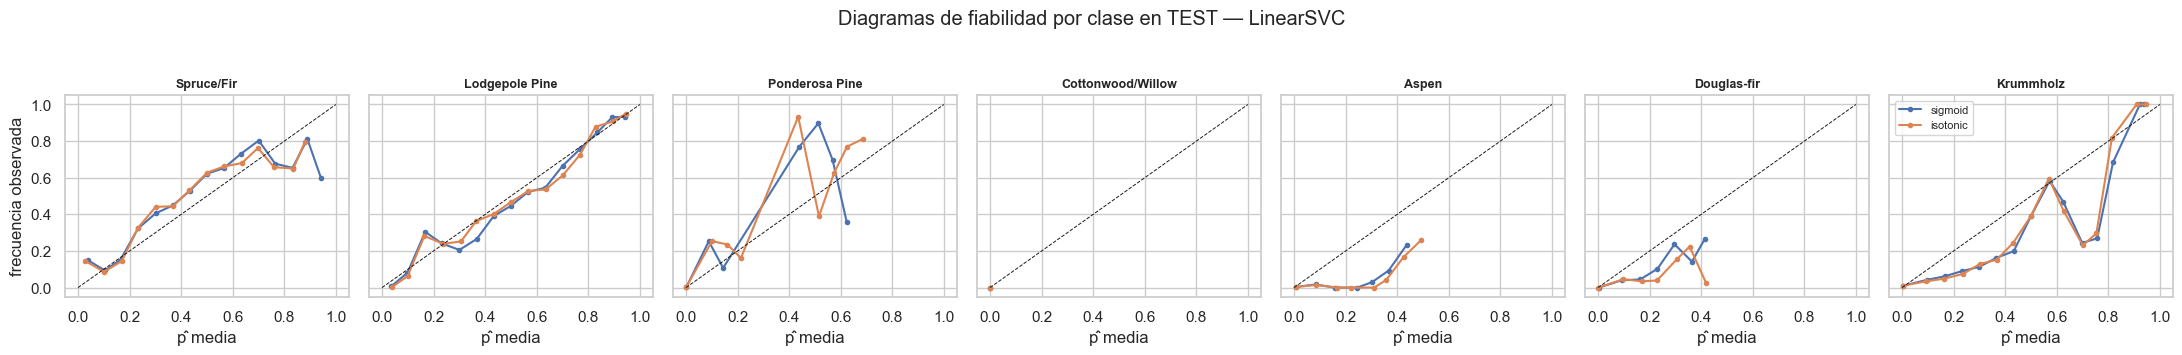

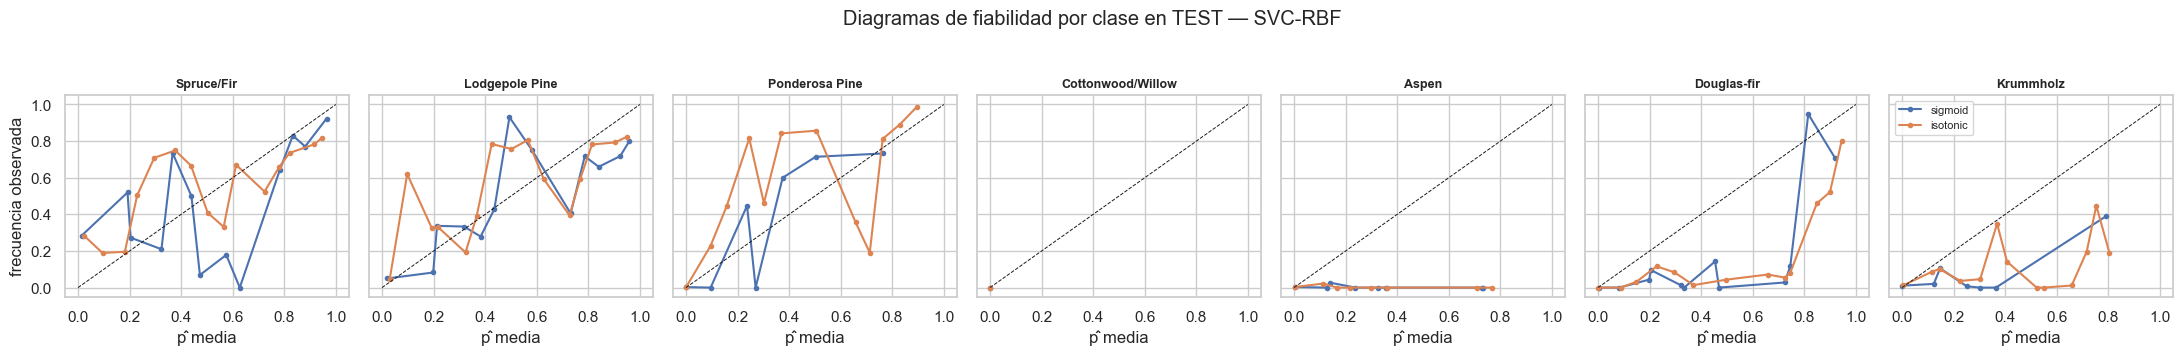

In [26]:
cal_rows = []
for (name, method), P in PROBA.items():
    for split, yt in [("IID", y_iid), ("TEST", y_test)]:
        p = P[split.lower()]
        cal_rows.append({"modelo": name, "método": method, "conjunto": split,
                         "ECE (15)": CAL.ece(p, yt, CLASSES, cc["ece_bins"]),
                         "ECE por clase (media)": CAL.classwise_ece(p, yt, CLASSES, cc["ece_bins"]).mean(),
                         "Brier": CAL.brier_multiclass(p, yt, CLASSES), "log-loss": log_loss(yt, np.clip(p, 1e-12, 1), labels=CLASSES),
                         "macro-F1": V.scores(yt, CLASSES[p.argmax(1)])["macro_f1"]})
calt = pd.DataFrame(cal_rows).sort_values(["modelo", "conjunto", "método"]); display(calt.round(4))
RESULTS["calibration"] = calt.to_dict("records"); RESULTS["calibration_method"] = METHOD

for name in [CHAMPION, ALT]:
    fig, axs = plt.subplots(1, 7, figsize=(22, 3.4), sharey=True)
    for method in [m for (n, m) in PROBA if n == name]:
        rt = CAL.reliability_table(PROBA[(name, method)]["test"], y_test, CLASSES, cc["ece_bins"])
        for k, c in enumerate(CLASSES):
            r = rt[rt["class"] == c]; axs[k].plot(r.mean_pred, r.frac_pos, "o-", ms=3, label=method)
    for k, a in enumerate(axs):
        a.plot([0, 1], [0, 1], "k--", lw=.7); a.set_title(NAMES[k], fontsize=9); a.set_xlabel("p̂ media")
    axs[0].set_ylabel("frecuencia observada"); axs[-1].legend(fontsize=8)
    fig.suptitle(f"Diagramas de fiabilidad por clase en TEST — {name}", y=1.04)
    plt.tight_layout(); savefig(f"17_fiabilidad_{name}"); plt.show()

### 6.2 Predicción conforme dividida (α = 0.1)
Puntajes de no conformidad $s_i = 1-\hat p(y_i\mid x_i)$ sobre **CAL** (10 000 filas que el modelo nunca vio), cuantil
$\hat q$ de orden $\lceil (n+1)(1-\alpha)\rceil/n$ y conjunto $\mathcal C_\alpha(x)=\{k:\hat p(k\mid x)\ge 1-\hat q\}$. Se evalúa en
**IID** (intercambiable con CAL: la garantía aplica) y en **TEST** (bloques nuevos: la garantía *no* aplica). Se añade la
variante **Mondrian** (un cuantil por clase), que apunta a cobertura condicional por clase.

,modelo,conjunto,q̂,cobertura,tamaño medio,% singleton,cobertura Mondrian,tamaño Mondrian
0,LinearSVC,IID,0.7634,0.8986,1.5510,45.4050,0.9020,1.9046
1,LinearSVC,TEST,0.7634,0.8978,1.6057,39.8822,0.8886,1.7561
2,SVC-RBF,IID,0.7944,0.8997,1.4874,51.5750,0.9002,1.6452
3,SVC-RBF,TEST,0.7944,0.8157,1.4412,56.9898,0.7742,1.4710


cobertura                       cobertura Mondrian                      
modelo            LinearSVC        SVC-RBF                 LinearSVC        SVC-RBF       
conjunto                IID   TEST     IID   TEST                IID   TEST     IID   TEST
clase                                                                                     
Aspen                 0.204  0.083   0.276  0.000              0.899  0.824   0.899  0.459
Cottonwood/Willow     0.685    NaN   0.855    NaN              0.879    NaN   0.927    NaN
Douglas-fir           0.679  0.595   0.845  0.548              0.894  0.839   0.912  0.914
Krummholz             0.862  0.800   0.857  0.705              0.946  0.854   0.930  0.814
Lodgepole Pine        0.946  0.924   0.990  0.975              0.905  0.884   0.897  0.760
Ponderosa Pine        0.944  0.512   0.973  0.599              0.897  0.510   0.913  0.299
Spruce/Fir            0.892  0.899   0.795  0.687              0.897  0.903   0.898  0.792

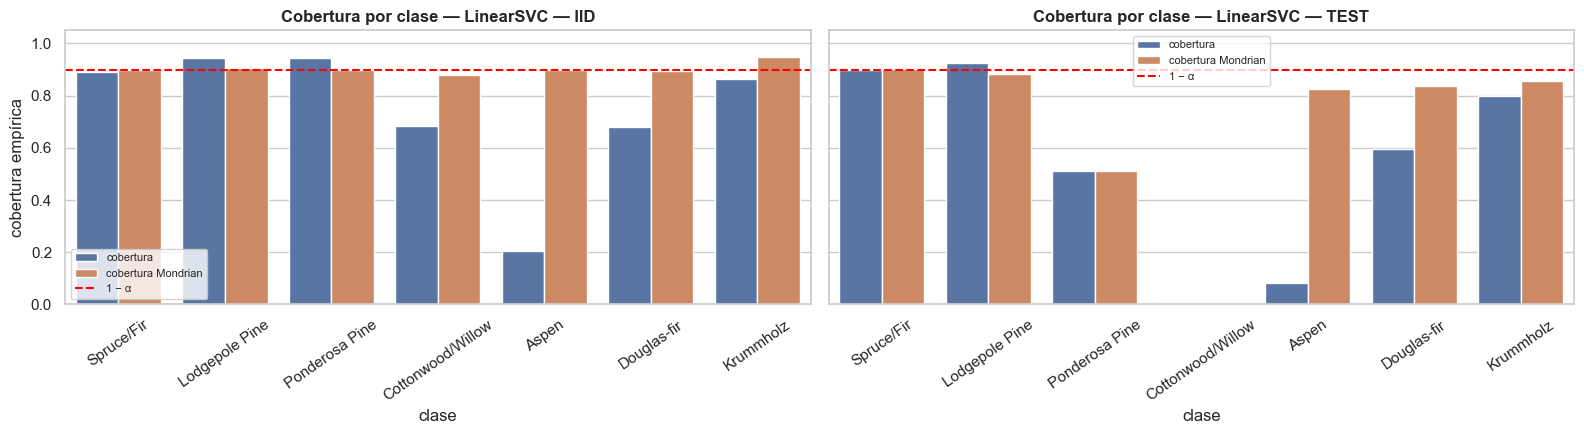

Tiempo acumulado: 97.9 min


In [27]:
alpha = cc["conformal_alpha"]
CONF, conf_rows, conf_class = {}, [], []
y_cal = y[cal_idx]
for name in [CHAMPION, ALT]:
    P = PROBA[(name, METHOD[name])]
    cp = CAL.SplitConformal(alpha).fit(P["cal"], y_cal, CLASSES)
    # Mondrian: un q̂ por clase verdadera (garantía condicional a la clase)
    q_k = {}
    for k, c in enumerate(CLASSES):
        sk = 1 - P["cal"][y_cal == c, k]; nk = len(sk)
        q_k[int(c)] = float(np.quantile(sk, min(1, np.ceil((nk + 1) * (1 - alpha)) / nk), method="higher")) if nk > 0 else 1.0
    CONF[name] = {"qhat": cp.qhat_, "alpha": alpha, "n_cal": cp.n_cal_, "method": METHOD[name], "mondrian_qhat": q_k}
    for split, yt in [("IID", y_iid), ("TEST", y_test)]:
        p = P[split.lower()]
        r = cp.evaluate(p, yt)
        setsM = p >= 1 - np.array([q_k[int(c)] for c in CLASSES])[None, :]
        setsM[np.arange(len(p)), p.argmax(1)] = True
        covM = setsM[np.arange(len(yt)), np.searchsorted(CLASSES, yt)]
        conf_rows.append({"modelo": name, "conjunto": split, "q̂": cp.qhat_, "cobertura": r["coverage"], "tamaño medio": r["avg_size"],
                          "% singleton": 100 * r["singleton_rate"], "cobertura Mondrian": covM.mean(), "tamaño Mondrian": setsM.sum(1).mean()})
        for c, d in r["per_class"].items():
            conf_class.append({"modelo": name, "conjunto": split, "clase": F.CLASS_NAMES[c], "cobertura": d["coverage"], "tamaño": d["avg_size"],
                               "cobertura Mondrian": covM[yt == c].mean() if (yt == c).any() else np.nan, "n": d["n"]})
conf = pd.DataFrame(conf_rows); confc = pd.DataFrame(conf_class)
display(conf.round(4)); display(confc.pivot_table(index="clase", columns=["modelo", "conjunto"], values=["cobertura", "cobertura Mondrian"]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for a, split in zip(ax, ["IID", "TEST"]):
    d = confc[(confc.conjunto == split) & (confc.modelo == CHAMPION)].melt(id_vars="clase", value_vars=["cobertura", "cobertura Mondrian"])
    sns.barplot(data=d, x="clase", y="value", hue="variable", ax=a, order=NAMES)
    a.axhline(1 - alpha, color="red", ls="--", label="1 − α"); a.set_title(f"Cobertura por clase — {CHAMPION} — {split}")
    a.tick_params(axis="x", rotation=35); a.set_ylabel("cobertura empírica"); a.set_ylim(0, 1.05); a.legend(fontsize=8)
plt.tight_layout(); savefig("18_conformal"); plt.show()
RESULTS["conformal"] = conf.to_dict("records"); RESULTS["conformal_class"] = confc.to_dict("records")
log_run("fase6-calibracion", metrics={f"cov_{r['modelo']}_{r['conjunto']}": r["cobertura"] for r in conf_rows},
        artifacts=[FIG / "18_conformal.png"])
print("Tiempo acumulado:", elapsed())

## 7. Fase 9 — Ingeniería y despliegue
Se exportan los artefactos versionados que consumen la API (`src/forest/api.py`) y el dashboard (`app/dashboard.py`):

| Artefacto | Contenido |
|---|---|
| `model.joblib` | Campeón calibrado (pipeline completo con `predict_proba`) |
| `model_alt.joblib` | Modelo alternativo calibrado (SVM o HGB) |
| `feature_names.json` | Las 54 variables en el orden de entrenamiento |
| `conformal.json` | q̂ global y Mondrian por modelo, α y método de calibración |
| `reference.csv.gz` | Muestra de referencia (CAL) para el monitoreo de deriva |
| `sample_batch.csv` | Lote de ejemplo (1 000 filas de TEST con etiqueta) para probar el dashboard |
| `results.json` | Resultados del notebook para el panel de resultados |
| `model_card.md` | Tarjeta del modelo |

In [28]:
deployed = CALIB[(CHAMPION, METHOD[CHAMPION])]
alt_model = CALIB[(ALT, METHOD[ALT])]
joblib.dump(deployed, ART / "model.joblib", compress=3)
joblib.dump(alt_model, ART / "model_alt.joblib", compress=3)
(ART / "feature_names.json").write_text(json.dumps(F.FEATURES), encoding="utf-8")
(ART / "conformal.json").write_text(json.dumps({"model": {**CONF[CHAMPION], "name": CHAMPION},
                                                 "model_alt": {**CONF[ALT], "name": ALT}}, indent=1), encoding="utf-8")
ref_rows = np.random.default_rng(SEED).choice(cal_idx, size=min(5000, len(cal_idx)), replace=False)
ref = X.iloc[ref_rows].copy(); ref["pred"] = deployed.predict(ref[F.FEATURES])
ref.to_csv(ART / "reference.csv.gz", index=False, compression="gzip")
sb = np.random.default_rng(SEED + 1).choice(test_idx, size=1000, replace=False)
df.iloc[sb].to_csv(ART / "sample_batch.csv", index=False)
for f in sorted(ART.iterdir()):
    print(f"{f.name:<22} {f.stat().st_size/2**20:7.2f} MB")

conformal.json            0.00 MB
feature_names.json        0.00 MB
model.joblib              0.02 MB
model_alt.joblib          0.67 MB
model_card.md             0.00 MB
reference.csv.gz          0.10 MB
results.json              0.04 MB
sample_batch.csv          0.13 MB


In [29]:
import subprocess
from fastapi.testclient import TestClient
from src.forest.api import app as api_app
with TestClient(api_app) as client:
    print("GET /health ->", client.get("/health").json())
    r = client.post("/predict", json={"instances": X_test.head(3).astype(float).values.tolist()})
    body = r.json(); print("POST /predict ->", r.status_code, {k: body[k] for k in ["cover_type", "prediction_sets", "classes"]})
    print("Probabilidades fila 1:", body["probabilities"][0], "| real:", y_test[:3].tolist())
    print("Fila con 3 valores ->", client.post("/predict", json={"instances": [[1.0, 2.0, 3.0]]}).status_code)

res = subprocess.run([sys.executable, "-m", "pytest", "-q", "--cov=src", "--cov-report=term-missing:skip-covered", "tests"],
                     capture_output=True, text=True, cwd=ROOT)
print(res.stdout[-2500:]); print(res.stderr[-800:])

C:\Users\ESTUDIANTE\Downloads\forest-cover-svm\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


GET /health -> {'status': 'ok'}
POST /predict -> 200 {'cover_type': [2, 2, 2], 'prediction_sets': [[2], [2], [2]], 'classes': [1, 2, 3, 4, 5, 6, 7]}
Probabilidades fila 1: [0.0847, 0.8977, 0.0, 0.0, 0.0176, 0.0, 0.0] | real: [2, 2, 2]
Fila con 3 valores -> 422


................                                                         [100%]
=============================== tests coverage ================================
_______________ coverage: platform win32, python 3.11.9-final-0 _______________

Name    Stmts   Miss  Cover   Missing
-------------------------------------
TOTAL     491      0   100%

8 files skipped due to complete coverage.
16 passed in 12.92s




## 8. Fase 10 (extensión) — Monitoreo y deriva (PI4)
**Referencia:** CAL (variables continuas + clases predichas por el modelo desplegado). **Ventanas** de 500 peticiones.
**Detectores:** PSI por variable (umbral 0.2), KS por variable con corrección de Holm (α = 0.05) y divergencia de
Jensen–Shannon entre la distribución de clases predichas y la de referencia (umbral 0.05).
**Escenarios:** (i) sin deriva (δ = 0, mide falsas alarmas), (ii) elevación desplazada δ ∈ {0.1, 0.25, 0.5} DE,
(iii) cambio de proporciones de clase (más Ponderosa, Cottonwood, Aspen y Douglas-fir) y (iv) deriva **real**: ventanas
tomadas de los bloques de TEST.

In [30]:
dr = cfg["drift"]; W = dr["window"]; NW = dr["n_windows"]
ref_X = X.iloc[cal_idx][F.CONTINUOUS]
ref_pred = CLASSES[PROBA[(CHAMPION, METHOD[CHAMPION])]["cal"].argmax(1)]
monitor = D.DriftMonitor(ref_X, F.CONTINUOUS, ref_pred, CLASSES, psi_threshold=dr["psi_threshold"], alpha=dr["alpha"])
sd_elev = float(X.iloc[devtrain_idx]["Elevation"].std())
rng = np.random.default_rng(SEED)
prior_w = {1: 1, 2: 1, 3: 3, 4: 6, 5: 4, 6: 3, 7: 1}
base_w = {int(c): float(v) for c, v in zip(CLASSES, np.bincount(y_iid, minlength=8)[1:] / len(y_iid))}
shift_w = {c: base_w[c] * prior_w[c] for c in base_w}

def window(scenario, delta=0.0):
    if scenario == "prior":
        idx = iid_idx[D.resample_priors(y_iid, shift_w, W, rng)]
    elif scenario == "test":
        idx = rng.choice(test_idx, W, replace=False)
    else:
        idx = rng.choice(iid_idx, W, replace=False)
    w = X.iloc[idx]
    if delta:
        w = D.shift_feature(w, "Elevation", delta, sd_elev)
    return w, y[idx]

drift_rows = []
scen = [(f"elevación δ={d}", "iid", d) for d in dr["deltas"]] + [("cambio de priors", "prior", 0.0), ("bloques TEST (real)", "test", 0.0)]
for label, sname, delta in scen:
    for i in range(NW):
        w, yw = window(sname, delta)
        pred = deployed.predict(w)
        r = monitor.check(w[F.CONTINUOUS], pred)
        drift_rows.append({"escenario": label, "ventana": i, "PSI máx": r["max_psi"], "variable PSI máx": r["psi_feature"],
                           "PSI elevación": float(r["table"].set_index("feature").loc["Elevation", "psi"]),
                           "p Holm mín": r["min_p_holm"], "JS clases": r["js"], "alerta PSI": r["psi_alert"],
                           "alerta KS": r["ks_alert"], "alerta JS": r["js_alert"], "alerta": r["alert"],
                           "macro-F1 ventana": V.scores(yw, pred)["macro_f1"]})
drift = pd.DataFrame(drift_rows)
power = drift.groupby("escenario", sort=False)[["alerta PSI", "alerta KS", "alerta JS", "alerta", "PSI elevación", "JS clases", "macro-F1 ventana"]].mean()
display(Markdown(f"**Tasa de alerta por ventana ({NW} ventanas de {W} peticiones).** Para δ = 0 es la tasa de falsas alarmas; en los demás, la potencia."))
display(power.round(3))

**Tasa de alerta por ventana (40 ventanas de 500 peticiones).** Para δ = 0 es la tasa de falsas alarmas; en los demás, la potencia.

,alerta PSI,alerta KS,alerta JS,alerta,PSI elevación,JS clases,macro-F1 ventana
escenario,,,,,,,
elevación δ=0.0,0.000,0.025,0.0,0.025,0.018,0.003,0.531
elevación δ=0.1,0.000,0.275,0.0,0.275,0.034,0.003,0.501
elevación δ=0.25,0.000,1.000,0.0,1.000,0.113,0.010,0.522
elevación δ=0.5,1.000,1.000,0.0,1.000,0.356,0.034,0.477
cambio de priors,0.325,1.000,0.0,1.000,0.181,0.029,0.522
bloques TEST (real),1.000,1.000,1.0,1.000,1.596,0.070,0.452


**Tiempo hasta la alerta**: 5 ventanas sin deriva y luego hasta 15 con deriva (15 repeticiones). `mediana_ventanas` = ventanas de 500 peticiones desde el inicio de la deriva.

,detectada,mediana_ventanas,media_ventanas,falsas_previas,mediana peticiones
escenario,,,,,
elevación δ=0.1,1.0,2.0,3.47,0.20,1000.0
elevación δ=0.25,1.0,1.0,1.00,0.20,500.0
elevación δ=0.5,1.0,1.0,1.00,0.07,500.0
cambio de priors,1.0,1.0,1.00,0.00,500.0
bloques TEST (real),1.0,1.0,1.00,0.20,500.0


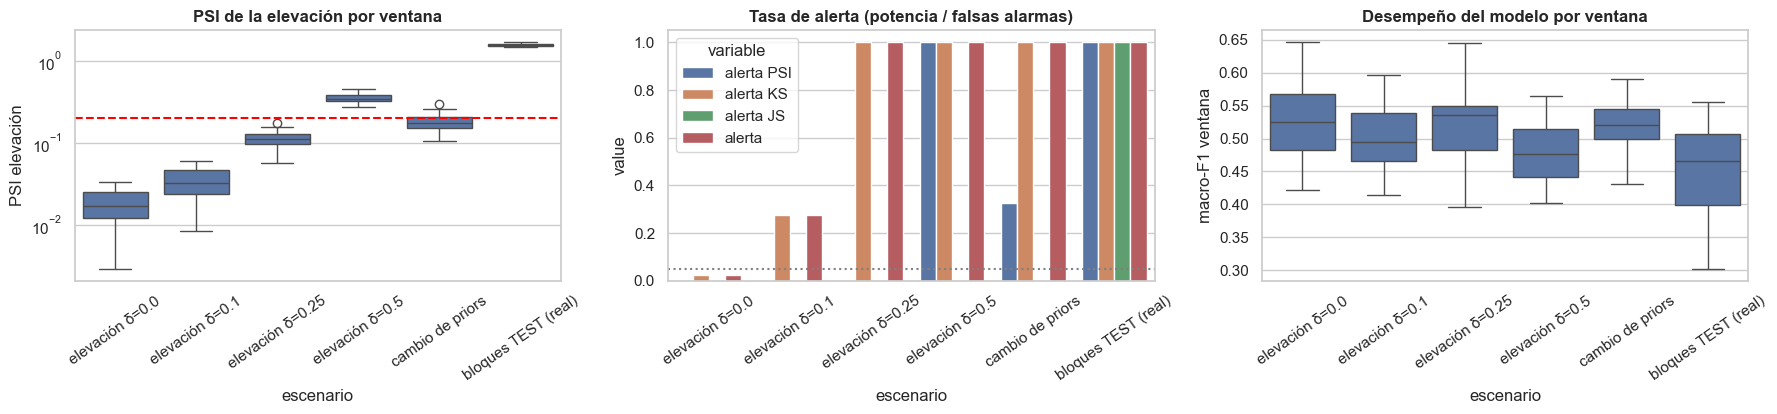

Tiempo acumulado: 99.1 min


In [31]:
# Tiempo hasta la alerta: flujo de 10 ventanas sin deriva seguido de ventanas con deriva (máx. 20), repetido 20 veces
tta_rows = []
n_rep, PRE, POST = (15, 5, 15) if PROFILE == "full" else (2, 2, 3)
for label, sname, delta in scen[1:]:
    for rep in range(n_rep):
        first_alert, false_pre = None, 0
        for i in range(PRE + POST):
            pre = i < PRE
            w, _ = window("iid" if pre else sname, 0.0 if pre else delta)
            alert = monitor.check(w[F.CONTINUOUS], deployed.predict(w))["alert"]
            if pre:
                false_pre += int(alert)
            elif alert:
                first_alert = i - PRE + 1; break
        tta_rows.append({"escenario": label, "rep": rep, "ventanas hasta alerta": first_alert,
                         "detectada": first_alert is not None, "falsas alarmas previas": false_pre})
tta = pd.DataFrame(tta_rows)
tt = tta.groupby("escenario", sort=False).agg(detectada=("detectada", "mean"), mediana_ventanas=("ventanas hasta alerta", "median"),
                                              media_ventanas=("ventanas hasta alerta", "mean"), falsas_previas=("falsas alarmas previas", "mean"))
tt["mediana peticiones"] = tt["mediana_ventanas"] * W
display(Markdown(f"**Tiempo hasta la alerta**: {PRE} ventanas sin deriva y luego hasta {POST} con deriva ({n_rep} repeticiones). "
                 "`mediana_ventanas` = ventanas de 500 peticiones desde el inicio de la deriva.")); display(tt.round(2))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
sns.boxplot(data=drift, x="escenario", y="PSI elevación", ax=ax[0]); ax[0].axhline(dr["psi_threshold"], color="red", ls="--")
ax[0].set_yscale("log"); ax[0].set_title("PSI de la elevación por ventana"); ax[0].tick_params(axis="x", rotation=35)
pw = power[["alerta PSI", "alerta KS", "alerta JS", "alerta"]].reset_index().melt(id_vars="escenario")
sns.barplot(data=pw, x="escenario", y="value", hue="variable", ax=ax[1]); ax[1].set_title("Tasa de alerta (potencia / falsas alarmas)")
ax[1].tick_params(axis="x", rotation=35); ax[1].axhline(dr["alpha"], color="gray", ls=":")
sns.boxplot(data=drift, x="escenario", y="macro-F1 ventana", ax=ax[2]); ax[2].set_title("Desempeño del modelo por ventana")
ax[2].tick_params(axis="x", rotation=35)
plt.tight_layout(); savefig("19_deriva"); plt.show()
RESULTS["drift_power"] = power.reset_index().to_dict("records"); RESULTS["drift_tta"] = tt.reset_index().to_dict("records")
RESULTS["drift_config"] = {"window": W, "psi_threshold": dr["psi_threshold"], "alpha": dr["alpha"], "sd_elevation": sd_elev}
log_run("fase10-deriva", metrics={f"power_{i}": v for i, v in enumerate(power["alerta"])}, artifacts=[FIG / "19_deriva.png"])
print("Tiempo acumulado:", elapsed())

**Política de alertas y reentrenamiento (definida a partir de los criterios del protocolo):**

| Señal | Acción |
|---|---|
| 1 ventana con alerta | Registrar; revisar la variable con mayor PSI. No se reentrena por una sola ventana (controla falsas alarmas). |
| 3 de las últimas 5 ventanas con alerta, o PSI > 0.25 en la elevación | **Alerta operativa**: etiquetar una muestra de 500 parcelas recientes y medir macro-F1. |
| macro-F1 etiquetado < (macro-F1 de TEST − 0.05) o cobertura conforme < 0.85 | **Reentrenar** con los datos nuevos etiquetados y recalibrar q̂ con un CAL reciente. |
| Deriva solo en priors (JS alta, PSI baja) | Recalibrar probabilidades/priors sin reentrenar el modelo base. |

In [32]:
RESULTS["fit_time"] = FIT_TIME
RESULTS["elapsed_min"] = (time.perf_counter() - T0) / 60
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return to_py(o.tolist())
    return o
(ART / "results.json").write_text(json.dumps(to_py(RESULTS), ensure_ascii=False, indent=1), encoding="utf-8")

champ_row = ev.set_index("modelo").loc[CHAMPION]
cal_row = calt[(calt["modelo"] == CHAMPION) & (calt["conjunto"] == "TEST") & (calt["método"] == METHOD[CHAMPION])].iloc[0]
cf = conf.set_index(["modelo", "conjunto"])
card = f'''# Tarjeta del modelo — Cobertura forestal (Forest CoverType)

**Versión:** 1.0.0 · **Modelo desplegado:** {CHAMPION} calibrado ({METHOD[CHAMPION]}, `CalibratedClassifierCV`, cv=5) · **Alternativo:** {ALT} calibrado ({METHOD[ALT]})

## Uso previsto
Apoyo a la cartografía de cobertura forestal en zonas con variables cartográficas como las del Roosevelt National Forest (Colorado, EE. UU.).
Las predicciones son **insumos** para decisiones de conservación y ordenamiento, siempre acompañadas del conjunto de predicción conforme.
**No** debe usarse fuera de la región de origen sin revalidar, ni como única fuente para decisiones irreversibles.

## Datos
UCI Covertype: 581 012 parcelas de 30 × 30 m, 54 variables (10 continuas, 4 áreas silvestres, 40 tipos de suelo), 7 clases desbalanceadas
(razón {ratio:.0f}:1). SHA-256 `{digest[:16]}…`. Partición por **bloques pseudo-espaciales** (KMeans k=20); prueba = bloques no vistos.

## Métricas (TEST, bloques no vistos)
| Métrica | Valor |
|---|---|
| macro-F1 | {champ_row['macro-F1 TEST']:.3f} |
| balanced accuracy | {champ_row['bal.acc TEST']:.3f} |
| MCC | {champ_row['MCC TEST']:.3f} |
| AUC macro (OvR) | {champ_row['AUC macro']:.3f} |
| macro-F1 en IID (misma distribución) | {champ_row['macro-F1 IID']:.3f} |
| ECE (15 intervalos, calibrado) | {cal_row['ECE (15)']:.3f} |
| Cobertura conforme α=0.1 (IID / TEST) | {cf.loc[(CHAMPION, 'IID'), 'cobertura']:.3f} / {cf.loc[(CHAMPION, 'TEST'), 'cobertura']:.3f} |

Recall por clase en TEST: ''' + ", ".join(f"{n}: {v:.2f}" for n, v in rec_tab.loc[CHAMPION].items()) + f'''

## Limitaciones
- Los bloques son pseudo-espaciales (no hay coordenadas): aproximan, no garantizan, independencia espacial.
- El desempeño cae al pasar de IID a bloques nuevos; la cobertura conforme solo está garantizada bajo intercambiabilidad.
- Clases raras (Cottonwood/Willow, Aspen) tienen menor recall y cobertura condicional; usar el conjunto conforme o Mondrian.
- La SVM exacta se entrenó con {fn['svc_train_size']:,} filas por su costo ≈ cuadrático; HGB con {fn['hgb_train_size']:,} (límite de memoria).

## Consideraciones éticas
Errores en coberturas raras (riparias como Cottonwood/Willow) pueden ocultar hábitats sensibles: no deben tomarse decisiones de
aprovechamiento con base solo en el modelo. El monitoreo de deriva (PSI/KS/JS) debe estar activo y la política de reentrenamiento documentada.
'''
(ART / "model_card.md").write_text(card, encoding="utf-8")
display(Markdown(card))
print(f"Tiempo total: {elapsed()}")

# Tarjeta del modelo — Cobertura forestal (Forest CoverType)

**Versión:** 1.0.0 · **Modelo desplegado:** LinearSVC calibrado (isotonic, `CalibratedClassifierCV`, cv=5) · **Alternativo:** SVC-RBF calibrado (sigmoid)

## Uso previsto
Apoyo a la cartografía de cobertura forestal en zonas con variables cartográficas como las del Roosevelt National Forest (Colorado, EE. UU.).
Las predicciones son **insumos** para decisiones de conservación y ordenamiento, siempre acompañadas del conjunto de predicción conforme.
**No** debe usarse fuera de la región de origen sin revalidar, ni como única fuente para decisiones irreversibles.

## Datos
UCI Covertype: 581 012 parcelas de 30 × 30 m, 54 variables (10 continuas, 4 áreas silvestres, 40 tipos de suelo), 7 clases desbalanceadas
(razón 103:1). SHA-256 `614360d0257557dd…`. Partición por **bloques pseudo-espaciales** (KMeans k=20); prueba = bloques no vistos.

## Métricas (TEST, bloques no vistos)
| Métrica | Valor |
|---|---|
| macro-F1 | 0.441 |
| balanced accuracy | 0.433 |
| MCC | 0.442 |
| AUC macro (OvR) | 0.894 |
| macro-F1 en IID (misma distribución) | 0.500 |
| ECE (15 intervalos, calibrado) | 0.036 |
| Cobertura conforme α=0.1 (IID / TEST) | 0.899 / 0.898 |

Recall por clase en TEST: Spruce/Fir: 0.61, Lodgepole Pine: 0.77, Ponderosa Pine: 0.51, Cottonwood/Willow: 0.00, Aspen: 0.01, Douglas-fir: 0.06, Krummholz: 0.63

## Limitaciones
- Los bloques son pseudo-espaciales (no hay coordenadas): aproximan, no garantizan, independencia espacial.
- El desempeño cae al pasar de IID a bloques nuevos; la cobertura conforme solo está garantizada bajo intercambiabilidad.
- Clases raras (Cottonwood/Willow, Aspen) tienen menor recall y cobertura condicional; usar el conjunto conforme o Mondrian.
- La SVM exacta se entrenó con 20,000 filas por su costo ≈ cuadrático; HGB con 150,000 (límite de memoria).

## Consideraciones éticas
Errores en coberturas raras (riparias como Cottonwood/Willow) pueden ocultar hábitats sensibles: no deben tomarse decisiones de
aprovechamiento con base solo en el modelo. El monitoreo de deriva (PSI/KS/JS) debe estar activo y la política de reentrenamiento documentada.


Tiempo total: 99.1 min


## 9. Respuestas a las preguntas de investigación, limitaciones y conclusiones
El texto de esta sección se genera a partir de `RESULTS`: cada cifra es la que produjo esta ejecución, con el esquema
de validación que la originó y su incertidumbre.

In [33]:
R = RESULTS
f3 = lambda v: f"{v:.3f}"
pct = lambda v: f"{100 * v:.1f} %"
vs = pd.DataFrame(R["validation_schemes"]).pivot(index="model", columns="scheme", values="mean")
op = pd.DataFrame(R["optimism"]).set_index("modelo")
cx = pd.DataFrame(R["complexity_fit"]).set_index("kernel")
ap = pd.DataFrame(R["approximations"]).set_index("modelo")
evt = pd.DataFrame(R["test_metrics"]).set_index("modelo")
cit = pd.DataFrame(R["test_ci"]).query("metric == 'macro_f1'").set_index("modelo")
sel = R["selection"]
mcn_ = pd.DataFrame(R["mcnemar"])
cal_ = pd.DataFrame(R["calibration"])
cfm = pd.DataFrame(R["conformal"]).set_index(["modelo", "conjunto"])
cfc = pd.DataFrame(R["conformal_class"])
dp = pd.DataFrame(R["drift_power"]).set_index("escenario")
dt = pd.DataFrame(R["drift_tta"]).set_index("escenario")
sc_ = pd.DataFrame(R["scalability"])
pick = lambda prefix: ap.loc[[i for i in ap.index if i.startswith(prefix)][0]]
ny, rff, svc_ex, hgb_ap = pick(f"Nyström m={best_m} "), pick(f"RFF m={best_m} "), pick("SVC-RBF exacta"), ap.loc["HGB"]
big = sc_[sc_.n == sc_.n.max()].set_index("kernel")
n_big = int(sc_.n.max())

# ---------- PI1 ----------
pi1 = f'''### PI1 · Escalabilidad
- **SVM exacta.** El exponente empírico del tiempo de ajuste es **b = {f3(cx.loc["linear", "b (ajuste)"])}** (lineal),
  **{f3(cx.loc["rbf", "b (ajuste)"])}** (RBF) y **{f3(cx.loc["poly", "b (ajuste)"])}** (polinómico); el IC 95 % del RBF,
  [{f3(cx.loc["rbf", "IC95 inf"])}, {f3(cx.loc["rbf", "IC95 sup"])}], {"es compatible con" if cx.loc["rbf", "IC95 sup"] >= 2 and cx.loc["rbf", "IC95 inf"] <= 3 else "queda fuera de"} el rango teórico b ∈ [2, 3].
  La predicción escala ≈ linealmente (b ≈ {f3(cx.loc["rbf", "b (predicción)"])}), porque su costo es proporcional al número de vectores de soporte.
  Con n = {n_big:,} la SVC-RBF ya tarda {big.loc["rbf", "fit_s"]:.1f} s y ocupa {big.loc["rbf", "fit_mem_mb"]:.0f} MB en el ajuste:
  extrapolar a las {R["partitions"]["DEV-TRAIN"]:,} filas de DEV-TRAIN (×{R["partitions"]["DEV-TRAIN"] / n_big:.0f}) con b ≈ 2 supone
  un costo ≈ {(R["partitions"]["DEV-TRAIN"] / n_big) ** 2:.0f} veces mayor, inviable en el equipo de desarrollo.
- **Aproximaciones de kernel** (todo DEV-TRAIN, {int(ny["n_train"]):,} filas): Nyström m = {best_m} logra macro-F1 =
  {f3(ny["macro_f1"])} en {ny["fit_s"]:.0f} s, frente a {f3(svc_ex["macro_f1"])} de la SVC-RBF exacta entrenada con
  {n_big:,} filas; RFF m = {best_m} logra {f3(rff["macro_f1"])}. Aumentar m mejora el desempeño a costa de tiempo
  (Nyström: m = 100 → {f3(pick("Nyström m=100 ")["macro_f1"])}; m = {best_m} → {f3(ny["macro_f1"])}).
- **Referencias:** HGB alcanza {f3(hgb_ap["macro_f1"])} ({hgb_ap["fit_s"]:.0f} s) y la regresión logística
  {f3(pick("LogReg")["macro_f1"])}. **Respuesta:** la SVM exacta no escala más allá de decenas de miles de filas; {"usar todos los datos con una aproximación de kernel compensa la pérdida de exactitud del kernel" if ny["macro_f1"] > svc_ex["macro_f1"] else "la aproximación de kernel no alcanza a la SVM exacta pese a usar más datos"}{", y el boosting sigue siendo la referencia más fuerte" if hgb_ap["macro_f1"] >= ap["macro_f1"].max() else ""}.
'''

# ---------- PI2 ----------
rows_opt = "\n".join(
    f"  | {m} | {f3(r['macro-F1 aleatorio'])} | {f3(r['macro-F1 bloques'])} | {f3(r['Δ (optimismo)'])} "
    f"[{f3(r['IC95 inf'])}, {f3(r['IC95 sup'])}] | {r['optimismo relativo %']:.0f} % |"
    for m, r in op.iterrows())
pi2 = f'''### PI2 · Validación aleatoria frente a validación por bloques
  | Modelo | macro-F1 aleatorio | macro-F1 bloques | Δ (IC 95 %, Nadeau–Bengio) | optimismo relativo |
  |---|---|---|---|---|
{rows_opt}

La validación aleatoria **sobreestima** el desempeño: las parcelas vecinas (casi idénticas en elevación y distancias)
caen a ambos lados de la partición y el modelo "reconoce" en vez de generalizar. La partición original de la UCI es
aún más optimista (HGB: {f3(vs.loc["HGB", "UCI"])}). La brecha se confirma en la prueba final: macro-F1 en IID (mismos
bloques que el entrenamiento) frente a TEST (bloques no vistos) es {f3(evt.loc["HGB", "macro-F1 IID"])} vs
{f3(evt.loc["HGB", "macro-F1 TEST"])} para HGB y {f3(evt.loc[CHAMPION, "macro-F1 IID"])} vs
{f3(evt.loc[CHAMPION, "macro-F1 TEST"])} para {CHAMPION}. **Respuesta:** el desempeño que se puede esperar en zonas
nuevas es el de la validación por bloques; las cifras aleatorias no deben reportarse como desempeño operativo.
'''

# ---------- Decisión y evaluación ----------
mrow = mcn_[(mcn_.A == CHAMPION) & (mcn_.B == ALT)]
mtxt = ""
if len(mrow):
    m0 = mrow.iloc[0]
    mtxt = (f"En TEST, McNemar {CHAMPION} vs {ALT}: χ² = {m0['chi2']:.1f}, p = {m0['p_value']:.2g}, razón de odds de "
            f"discordancia = {m0['odds_ratio']:.2f}; Δ macro-F1 = {f3(m0['Δ macro-F1'])} "
            f"[{f3(m0['IC95 Δ inf'])}, {f3(m0['IC95 Δ sup'])}].")
best_test = evt["macro-F1 TEST"].idxmax()
dec = f'''### Selección del campeón y evaluación final
- **Regla de la fase 0, aplicada con datos de desarrollo:** el mejor en la validación anidada fue **{sel["primero"]}**
  (macro-F1 = {f3(sel["macro_f1_primero"])}), seguido de **{sel["segundo"]}** ({f3(sel["macro_f1_segundo"])}).
  La diferencia {"**es**" if sel["significativa"] else "**no es**"} significativa (t corregida = {sel["t"]:.2f},
  p = {sel["p"]:.3f}, comparación {"pareada" if sel["pareada"] else "no pareada"}); {"se elige el de mayor macro-F1" if sel["significativa"]
  else f"se elige el más barato de servir ({sel['ms_1000_primero']:.1f} vs {sel['ms_1000_segundo']:.1f} ms por 1 000 filas)"}:
  **campeón = {CHAMPION}**.
- **TEST (bloques no vistos), evaluado una sola vez:** {CHAMPION} obtiene macro-F1 = {f3(evt.loc[CHAMPION, "macro-F1 TEST"])}
  (IC 95 % bootstrap [{f3(cit.loc[CHAMPION, "ci_low"])}, {f3(cit.loc[CHAMPION, "ci_high"])}]), balanced accuracy =
  {f3(evt.loc[CHAMPION, "bal.acc TEST"])} y MCC = {f3(evt.loc[CHAMPION, "MCC TEST"])}. El mejor macro-F1 en TEST es el de
  **{best_test}** ({f3(evt.loc[best_test, "macro-F1 TEST"])}). {mtxt}
'''
if best_test != CHAMPION:
    dec += f'''- **Por qué no se cambia el campeón tras ver TEST:** hacerlo convertiría TEST en un conjunto de selección y sus cifras
  dejarían de ser una estimación insesgada. La diferencia se reporta como hallazgo: la validación anidada usa submuestras de
  {cfg["tuning"]["svc_sample_size"]:,}–{cfg["tuning"]["hgb_sample_size"]:,} filas y su dispersión entre pliegues es grande,
  de modo que no separa con fiabilidad a los candidatos.
'''

# ---------- Análisis de errores ----------
cm_ = np.array(R["confusion"][CHAMPION])
absent = [NAMES[i] for i in range(len(CLASSES)) if cm_[i].sum() == 0]
err_lines = []
for i in range(len(CLASSES)):
    if cm_[i].sum() == 0:
        continue
    off = cm_[i].copy(); off[i] = 0
    j = int(off.argmax())
    if cm_[i, i] < 0.5:
        err_lines.append(f"  - **{NAMES[i]}**: recall {f3(cm_[i, i])}; el {pct(off[j])} se confunde con **{NAMES[j]}**.")
err = f'''### Análisis de errores ({CHAMPION}, TEST)
''' + ("\n".join(err_lines) if err_lines else "  - Ninguna clase presente tiene recall < 0.5.") + f'''
- Las confusiones se concentran entre coberturas que comparten franja altitudinal (las clases raras se absorben en las
  mayoritarias Lodgepole Pine y Spruce/Fir), lo que explica la distancia entre exactitud ({f3(evt.loc[CHAMPION, "exactitud TEST"])})
  y macro-F1.
''' + (f"- **{', '.join(absent)}** no aparece en los bloques de TEST (la clase está concentrada geográficamente), así que su "
       "desempeño no puede evaluarse fuera de distribución; el macro-F1 de TEST promedia las clases presentes.\n" if absent else "")

# ---------- PI3 ----------
def cal_get(model, method, split, col):
    r = cal_[(cal_["modelo"] == model) & (cal_["método"] == method) & (cal_["conjunto"] == split)]
    return float(r[col].iloc[0]) if len(r) else float("nan")
mc_ = METHOD[CHAMPION]
cc_t = cfc[(cfc.modelo == CHAMPION) & (cfc.conjunto == "TEST") & (cfc.n > 0)].sort_values("cobertura")
worst = ", ".join(f"{r['clase']} {f3(r['cobertura'])} (Mondrian {f3(r['cobertura Mondrian'])})" for _, r in cc_t.head(3).iterrows())
alt_unc = cal_get(ALT, "sin calibrar", "TEST", "ECE (15)")
alt_txt = (f" Para {ALT}, sin calibrar ECE en TEST = {f3(alt_unc)} y con {METHOD[ALT]} = {f3(cal_get(ALT, METHOD[ALT], 'TEST', 'ECE (15)'))}."
           if np.isfinite(alt_unc) else "")
pi3 = f'''### PI3 · Calibración y predicción conforme
- **Calibración** ({mc_}, elegida por la regla del protocolo): ECE (15 intervalos) de {CHAMPION} =
  {f3(cal_get(CHAMPION, mc_, "IID", "ECE (15)"))} en IID y {f3(cal_get(CHAMPION, mc_, "TEST", "ECE (15)"))} en TEST; Brier =
  {f3(cal_get(CHAMPION, mc_, "IID", "Brier"))} / {f3(cal_get(CHAMPION, mc_, "TEST", "Brier"))}.{alt_txt} La calibración se
  aprende en la distribución de entrenamiento: {"se degrada claramente" if cal_get(CHAMPION, mc_, "TEST", "ECE (15)") > 2 * cal_get(CHAMPION, mc_, "IID", "ECE (15)") else "se degrada poco"} en bloques no vistos.
- **Conforme dividida (α = {cfg["calibration"]["conformal_alpha"]})**: cobertura empírica de {CHAMPION} =
  **{f3(cfm.loc[(CHAMPION, "IID"), "cobertura"])}** en IID (garantía nominal {1 - cfg["calibration"]["conformal_alpha"]:.2f},
  tamaño medio {cfm.loc[(CHAMPION, "IID"), "tamaño medio"]:.2f}) y **{f3(cfm.loc[(CHAMPION, "TEST"), "cobertura"])}** en
  TEST (tamaño {cfm.loc[(CHAMPION, "TEST"), "tamaño medio"]:.2f}).
- **Respuesta:** la garantía solo está asegurada cuando CAL y los datos nuevos son intercambiables (IID). {"En los bloques no vistos la cobertura global se mantiene cerca de la nominal, pero no por garantía: el cambio de distribución altera qué clases quedan cubiertas." if cfm.loc[(CHAMPION, "TEST"), "cobertura"] >= 1 - cfg["calibration"]["conformal_alpha"] - 0.02 else "En los bloques no vistos la cobertura global **cae por debajo** de la nominal."} Además, la
  garantía es **marginal**: en TEST, las clases peor cubiertas son {worst}. La versión Mondrian (un cuantil por clase)
  apunta a la cobertura condicional por clase dentro de la distribución, pero tampoco la garantiza en bloques no vistos.
'''

# ---------- PI4 ----------
elev = [i for i in dp.index if i.startswith("elevación")]
d_rows = "\n".join(f"  | {i} | {pct(dp.loc[i, 'alerta'])} | {pct(dp.loc[i, 'alerta PSI'])} | {pct(dp.loc[i, 'alerta KS'])} | "
                   f"{dp.loc[i, 'PSI elevación']:.3f} |" for i in elev + [i for i in dp.index if i not in elev])
tta_rows = "\n".join(f"  | {i} | {pct(r['detectada'])} | {r['mediana_ventanas']:.0f} ({r['mediana peticiones']:.0f} peticiones) | "
                     f"{r['falsas_previas']:.2f} |" for i, r in dt.iterrows())
pi4 = f'''### PI4 · Monitoreo y deriva (ventanas de {R["drift_config"]["window"]} peticiones)
  | Escenario | alerta (cualquiera) | alerta PSI > {R["drift_config"]["psi_threshold"]} | alerta KS (Holm) | PSI elevación |
  |---|---|---|---|---|
{d_rows}

  | Escenario | detectada | mediana de ventanas hasta la alerta | falsas alarmas previas (media) |
  |---|---|---|---|
{tta_rows}

**Respuesta:** la tasa de falsas alarmas sin deriva es {pct(dp.loc[elev[0], "alerta"])} por ventana. El PSI con umbral
{R["drift_config"]["psi_threshold"]} solo es fiable para desplazamientos grandes; la prueba KS por variable con corrección de Holm
detecta desplazamientos menores y es la que fija el tiempo hasta la alerta. El cambio de proporciones de clase se
detecta por las covariables, mientras que la divergencia de Jensen–Shannon de las clases predichas reacciona poco.
Los bloques reales de TEST disparan todos los detectores, coherente con la caída de desempeño observada en PI2.
'''

lim = f'''### Limitaciones
- Los bloques son **pseudo-espaciales** (KMeans sobre elevación y distancias): el conjunto no trae coordenadas, así que
  aproximan, pero no garantizan, la separación geográfica.
- La SVM exacta y la búsqueda anidada usan **submuestras** ({cfg["final"]["svc_train_size"]:,} y
  {cfg["tuning"]["svc_sample_size"]:,} filas) por su costo ≈ cuadrático y por la memoria del equipo (7 GB); HGB se entrena
  con {cfg["final"]["hgb_train_size"]:,} filas.
- La validación anidada tiene solo 5 pliegues externos: la potencia para distinguir modelos es baja (ver la regla de selección).
- Las cifras dependen de la semilla {SEED}; no se repitió todo el estudio con varias semillas por costo de cómputo.
- Las clases raras tienen pocas observaciones en los bloques de prueba{" (" + ", ".join(absent) + ": ninguna)" if absent else ""}: sus
  métricas por clase son inestables.

### Conclusión
Bajo un protocolo sin fuga (todo lo aprendido vive en el `Pipeline`, verificado por pruebas automáticas) y con validación
por bloques, el desempeño honesto en zonas no vistas es muy inferior al que sugiere una validación aleatoria. La SVM con
kernel exacto no escala a este volumen; las aproximaciones de kernel y la SVM lineal permiten usar todos los datos. Las probabilidades
calibradas y los conjuntos conformes son fiables dentro de la distribución de entrenamiento, y el monitoreo detecta
el cambio de distribución que los invalida, lo que justifica la política de alertas y reentrenamiento de la §8.
'''
display(Markdown("\n\n".join([pi1, pi2, dec, err, pi3, pi4, lim])))

### PI1 · Escalabilidad
- **SVM exacta.** El exponente empírico del tiempo de ajuste es **b = 2.121** (lineal),
  **2.204** (RBF) y **2.232** (polinómico); el IC 95 % del RBF,
  [1.672, 2.736], es compatible con el rango teórico b ∈ [2, 3].
  La predicción escala ≈ linealmente (b ≈ 0.926), porque su costo es proporcional al número de vectores de soporte.
  Con n = 20,000 la SVC-RBF ya tarda 21.1 s y ocupa 473 MB en el ajuste:
  extrapolar a las 411,080 filas de DEV-TRAIN (×21) con b ≈ 2 supone
  un costo ≈ 422 veces mayor, inviable en el equipo de desarrollo.
- **Aproximaciones de kernel** (todo DEV-TRAIN, 333,974 filas): Nyström m = 1000 logra macro-F1 =
  0.485 en 37 s, frente a 0.290 de la SVC-RBF exacta entrenada con
  20,000 filas; RFF m = 1000 logra 0.403. Aumentar m mejora el desempeño a costa de tiempo
  (Nyström: m = 100 → 0.259; m = 1000 → 0.485).
- **Referencias:** HGB alcanza 0.590 (103 s) y la regresión logística
  0.334. **Respuesta:** la SVM exacta no escala más allá de decenas de miles de filas; usar todos los datos con una aproximación de kernel compensa la pérdida de exactitud del kernel, y el boosting sigue siendo la referencia más fuerte.


### PI2 · Validación aleatoria frente a validación por bloques
  | Modelo | macro-F1 aleatorio | macro-F1 bloques | Δ (IC 95 %, Nadeau–Bengio) | optimismo relativo |
  |---|---|---|---|---|
  | SVC-RBF | 0.675 | 0.413 | 0.262 [0.193, 0.331] | 63 % |
  | LogReg | 0.534 | 0.396 | 0.139 [-0.005, 0.282] | 35 % |
  | HGB | 0.712 | 0.358 | 0.354 [0.223, 0.484] | 99 % |

La validación aleatoria **sobreestima** el desempeño: las parcelas vecinas (casi idénticas en elevación y distancias)
caen a ambos lados de la partición y el modelo "reconoce" en vez de generalizar. La partición original de la UCI es
aún más optimista (HGB: 0.857). La brecha se confirma en la prueba final: macro-F1 en IID (mismos
bloques que el entrenamiento) frente a TEST (bloques no vistos) es 0.920 vs
0.488 para HGB y 0.500 vs
0.441 para LinearSVC. **Respuesta:** el desempeño que se puede esperar en zonas
nuevas es el de la validación por bloques; las cifras aleatorias no deben reportarse como desempeño operativo.


### Selección del campeón y evaluación final
- **Regla de la fase 0, aplicada con datos de desarrollo:** el mejor en la validación anidada fue **SVC-RBF**
  (macro-F1 = 0.406), seguido de **LinearSVC** (0.374).
  La diferencia **no es** significativa (t corregida = 0.68,
  p = 0.532, comparación pareada); se elige el más barato de servir (709.1 vs 4.5 ms por 1 000 filas):
  **campeón = LinearSVC**.
- **TEST (bloques no vistos), evaluado una sola vez:** LinearSVC obtiene macro-F1 = 0.441
  (IC 95 % bootstrap [0.430, 0.450]), balanced accuracy =
  0.433 y MCC = 0.442. El mejor macro-F1 en TEST es el de
  **HGB** (0.488). En TEST, McNemar LinearSVC vs SVC-RBF: χ² = 364.5, p = 2.9e-81, razón de odds de discordancia = 1.26; Δ macro-F1 = 0.037 [0.027, 0.047].
- **Por qué no se cambia el campeón tras ver TEST:** hacerlo convertiría TEST en un conjunto de selección y sus cifras
  dejarían de ser una estimación insesgada. La diferencia se reporta como hallazgo: la validación anidada usa submuestras de
  6,000–20,000 filas y su dispersión entre pliegues es grande,
  de modo que no separa con fiabilidad a los candidatos.


### Análisis de errores (LinearSVC, TEST)
  - **Aspen**: recall 0.015; el 89.4 % se confunde con **Lodgepole Pine**.
  - **Douglas-fir**: recall 0.061; el 84.2 % se confunde con **Lodgepole Pine**.
- Las confusiones se concentran entre coberturas que comparten franja altitudinal (las clases raras se absorben en las
  mayoritarias Lodgepole Pine y Spruce/Fir), lo que explica la distancia entre exactitud (0.680)
  y macro-F1.
- **Cottonwood/Willow** no aparece en los bloques de TEST (la clase está concentrada geográficamente), así que su desempeño no puede evaluarse fuera de distribución; el macro-F1 de TEST promedia las clases presentes.


### PI3 · Calibración y predicción conforme
- **Calibración** (isotonic, elegida por la regla del protocolo): ECE (15 intervalos) de LinearSVC =
  0.019 en IID y 0.036 en TEST; Brier =
  0.391 / 0.432. La calibración se
  aprende en la distribución de entrenamiento: se degrada poco en bloques no vistos.
- **Conforme dividida (α = 0.1)**: cobertura empírica de LinearSVC =
  **0.899** en IID (garantía nominal 0.90,
  tamaño medio 1.55) y **0.898** en
  TEST (tamaño 1.61).
- **Respuesta:** la garantía solo está asegurada cuando CAL y los datos nuevos son intercambiables (IID). En los bloques no vistos la cobertura global se mantiene cerca de la nominal, pero no por garantía: el cambio de distribución altera qué clases quedan cubiertas. Además, la
  garantía es **marginal**: en TEST, las clases peor cubiertas son Aspen 0.083 (Mondrian 0.824), Ponderosa Pine 0.512 (Mondrian 0.510), Douglas-fir 0.595 (Mondrian 0.839). La versión Mondrian (un cuantil por clase)
  apunta a la cobertura condicional por clase dentro de la distribución, pero tampoco la garantiza en bloques no vistos.


### PI4 · Monitoreo y deriva (ventanas de 500 peticiones)
  | Escenario | alerta (cualquiera) | alerta PSI > 0.2 | alerta KS (Holm) | PSI elevación |
  |---|---|---|---|---|
  | elevación δ=0.0 | 2.5 % | 0.0 % | 2.5 % | 0.018 |
  | elevación δ=0.1 | 27.5 % | 0.0 % | 27.5 % | 0.034 |
  | elevación δ=0.25 | 100.0 % | 0.0 % | 100.0 % | 0.113 |
  | elevación δ=0.5 | 100.0 % | 100.0 % | 100.0 % | 0.356 |
  | cambio de priors | 100.0 % | 32.5 % | 100.0 % | 0.181 |
  | bloques TEST (real) | 100.0 % | 100.0 % | 100.0 % | 1.596 |

  | Escenario | detectada | mediana de ventanas hasta la alerta | falsas alarmas previas (media) |
  |---|---|---|---|
  | elevación δ=0.1 | 100.0 % | 2 (1000 peticiones) | 0.20 |
  | elevación δ=0.25 | 100.0 % | 1 (500 peticiones) | 0.20 |
  | elevación δ=0.5 | 100.0 % | 1 (500 peticiones) | 0.07 |
  | cambio de priors | 100.0 % | 1 (500 peticiones) | 0.00 |
  | bloques TEST (real) | 100.0 % | 1 (500 peticiones) | 0.20 |

**Respuesta:** la tasa de falsas alarmas sin deriva es 2.5 % por ventana. El PSI con umbral
0.2 solo es fiable para desplazamientos grandes; la prueba KS por variable con corrección de Holm
detecta desplazamientos menores y es la que fija el tiempo hasta la alerta. El cambio de proporciones de clase se
detecta por las covariables, mientras que la divergencia de Jensen–Shannon de las clases predichas reacciona poco.
Los bloques reales de TEST disparan todos los detectores, coherente con la caída de desempeño observada en PI2.


### Limitaciones
- Los bloques son **pseudo-espaciales** (KMeans sobre elevación y distancias): el conjunto no trae coordenadas, así que
  aproximan, pero no garantizan, la separación geográfica.
- La SVM exacta y la búsqueda anidada usan **submuestras** (20,000 y
  6,000 filas) por su costo ≈ cuadrático y por la memoria del equipo (7 GB); HGB se entrena
  con 150,000 filas.
- La validación anidada tiene solo 5 pliegues externos: la potencia para distinguir modelos es baja (ver la regla de selección).
- Las cifras dependen de la semilla 42; no se repitió todo el estudio con varias semillas por costo de cómputo.
- Las clases raras tienen pocas observaciones en los bloques de prueba (Cottonwood/Willow: ninguna): sus
  métricas por clase son inestables.

### Conclusión
Bajo un protocolo sin fuga (todo lo aprendido vive en el `Pipeline`, verificado por pruebas automáticas) y con validación
por bloques, el desempeño honesto en zonas no vistas es muy inferior al que sugiere una validación aleatoria. La SVM con
kernel exacto no escala a este volumen; las aproximaciones de kernel y la SVM lineal permiten usar todos los datos. Las probabilidades
calibradas y los conjuntos conformes son fiables dentro de la distribución de entrenamiento, y el monitoreo detecta
el cambio de distribución que los invalida, lo que justifica la política de alertas y reentrenamiento de la §8.
